# US RIA Market Analysis for Nevis: Growth, Capacity & Staffing Signals
**Source:** SEC monthly Form ADV Part 1A roster ("Information About Registered Investment Advisers"), September 2021 to September 2026, plus November 2026 for current firm details.
**Author:** Justin McBryan · November 2026

### Executive summary
**The market (FY2025, as filed by Sep 2026):** 17,149 SEC-registered RIAs manage \$177T, but most of the top is asset managers (Vanguard, BlackRock, PIMCO), who aren't Nevis buyers. This analysis focuses on the **6,940 wealth managers** (\$21.4T): firms whose AUM is mainly from individuals and high-net-worth clients and who serve them through advisors. Wirehouses and broker-dealers are included and tagged.

| Segment (FY2025 AUM) | All SEC RIAs | Wealth managers | of which independent RIAs | of which dual-registered (BD) |
|---|---|---|---|---|
| <\$1B | 11,756 | 5,628 | 5,524 | 104 |
| \$1B-\$10B | 4,023 | 1,153 | 1,077 | 76 |
| \$10B-\$50B | 938 | 115 | 90 | 25 |
| >\$50B | 432 | 44 | 25 | 19 |
| **Total** | **17,149** | **6,940** | **6,716** | **224** |

**Key findings for Nevis**
1. **The capacity squeeze is near-universal.** Among \$1B+ wealth managers, **92% grew AUM faster than advisor headcount** over three years: median AUM growth of **18.1% a year vs 4.6%** for advisors. Each advisor is carrying more every year, which is the problem Nevis solves.
2. **The fastest sustained growers** include Waverly Advisors (\$5.8B → \$29.9B in 3 years), Pathstone (\$24.8B → \$110B), Arkadios, Apella and Merit Financial, compounding at 60-70%+ a year, far above the ~13% market-driven median.
3. **Capacity strain is highest where few advisors carry very large books.** A typical \$1B+ wealth manager runs ~\$120M-\$130M and 60-80 clients per advisor; outliers such as Circle Wealth (\$1.3B per advisor) and First Manhattan (\$750M) are the most stretched.
4. **Roll-ups are reshaping the top of the market.** About **half of \$10B+ wealth managers have a new controlling owner since 2020**, many backed by private equity (Focus Partners/CD&R, Hightower/THL, Mariner/Leonard Green, Cerity/Genstar). Newly combined firms need to standardise workflows across acquired teams.
5. **Two custodians are the channel.** Schwab and Fidelity each serve over half of \$10B+ wealth managers (Pershing ~17%), a natural partnership route.
6. **Enterprise targets** (growth + current strain + worsening strain): for \$50B+, Cresset, Pathstone, Focus Partners, MAI Capital, Carson, Savant, IEQ, Osaic, Fisher and Wells Fargo Advisors. For \$10B-\$50B, Aptus, RWA Wealth Partners and others (Section 6.3).

**Data robustness:** 22 automated checks (V0-V21) run on every execution and all pass (Section 1.4). They cover file fingerprints, schema, uniqueness, Form ADV arithmetic identities, reconciliation to SEC totals, cross-year linkage, classification of asset managers vs wealth managers, an IAPD spot check, and independent recomputation of growth rates.

**Deliverables:** this notebook · `outputs/nevis_ria_targets.xlsx` (every ranked list, data-check log, custodians, ownership change, full firm table) · `outputs/ria_firm_year_table.csv` (analysis-ready firm-year table, ~95k rows).

# 1. Overview
## 1.1 How this workbook is put together and how to run it
**Run it:** Runtime → **Run all** (about 4 minutes in Colab). The first run downloads seven SEC roster files (~75 MB) and the SEC bulk Form ADV archive (~1.1 GB, for custodians and ownership), then caches small extracts; reruns use the cache. Every table and chart is also saved in the notebook, so it can be read without running anything.

**Layout:** the Colab contents panel (☰, left sidebar) works as the navigation.

| Section | What it contains |
|---|---|
| **1. Overview** | How to run (1.1), the questions and why they matter (1.2), the data pipeline and method (1.3), data-integrity checks (1.4), code quality and AI use (1.5) |
| **2. Question 1** | RIAs by AUM market segment (FY2025) |
| **3. Question 2a** | Fastest-growing firms (1, 3, 5 years) |
| **4. Question 2b** | Capacity-strained firms (AUM per advisor) |
| **5. Question 3** | Under-staffed firms (AUM growth vs advisor growth) |
| **6. Additional data of value** | Custodians (6.1), ownership change / roll-ups (6.2), combined Nevis target list (6.3) |
| **7. Export** | Writes the Excel workbook and firm-year CSV |

**Design principle:** all calculations happen once in Section 1.3 (the *analysis engine*); Sections 2–6 only present results. This keeps the logic in one auditable place and lets Section 1.4 validate the calculations before anything is presented.

**Outputs:** `outputs/nevis_ria_targets.xlsx` (every ranked list, top 25 per segment, data-check log, full firm table) · `outputs/ria_firm_year_table.csv` (analysis-ready firm-year table, ~95k rows).

In [1]:
import os, re, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path(os.environ.get("NEVIS_DATA_DIR", "data"))
RAW, CACHE, OUT = DATA_DIR / "raw", DATA_DIR / "cache", Path("outputs")
for p in (RAW, CACHE, OUT): p.mkdir(parents=True, exist_ok=True)
# SEC fair-access policy: automated requests must identify a name and contact email
SEC_USER_AGENT = os.environ.get("SEC_USER_AGENT", "Justin McBryan justin.mcbryan@useaffluence.com")

## 1.2 The questions we are solving for, and why
Nevis sells AI that increases **advisor capacity** at RIAs. Each question in the brief maps to a buying signal:

| # | Question | Why it matters to Nevis |
|---|---|---|
| Q1 | How many RIAs fall into each AUM segment? | Sizes the market and tells us which go-to-market motion fits each tier (named-account Enterprise vs product-led) |
| Q2a | Who are the fastest-growing firms? | Growth means budget, urgency and new advisors to onboard |
| Q2b | Which firms are capacity-strained? | High AUM (and clients) per advisor means advisors are stretched today |
| Q3 | Which RIAs appear under-staffed? | AUM growing faster than headcount means the strain is getting **worse**, the clearest case for leverage per advisor |

Every question is answered twice: for **all SEC-registered RIAs** (the literal answer) and for **advisor-led wealth managers**, Nevis's ideal customer profile. Unfiltered rankings are dominated by fund managers that aren't Nevis buyers.

## 1.3 The process: from raw SEC filings to this view
**Pipeline:** download seven SEC snapshots → standardise 448 columns to the brief's fields → link firms across years by CRD# → clean and flag → validate (1.4) → compute metrics (analysis engine) → present (Sections 2–6).

### Step 1: Data sourcing, and why these files


| Choice | Reason |
|---|---|
| **Monthly SEC roster**, not the bulk ADV tables | One row per firm with every Part 1A answer already flattened into columns. Same fields as the bulk data, far less joining risk. |
| **One snapshot per year (September)** | Item 5 (AUM, clients, headcount) only has to be refreshed in the **annual updating amendment**, due within 90 days of fiscal year end (Form ADV General Instruction 4). Monthly files in between mostly repeat the same numbers. **Validated by CHECK V12:** 97.4% of firms have identical AUM in Sep and Nov 2026. |
| **September specifically** | It is after filing season, so nearly every firm has filed. It exists in all six years (Oct and Nov 2025 are "no data" on the SEC site). Every growth interval is exactly 12 months. |
| **November 2026 for firm identity** | Items 1 (name, address, **website**) must be amended *promptly* when they change, so the latest file holds the most current contact details. |

**Fiscal-year labelling:** a September 20XX snapshot holds AUM as of each firm's prior fiscal year end (December 20XX-1 for most firms). So the **Sep 2026 file = FY2025**, the latest full-year data set, and results are labelled by fiscal year (FY2020-FY2025). In the code, `year` is the snapshot year and `fiscal_year` = `year` − 1.

In [2]:
BASE = "https://www.sec.gov/files/investment/data/"
OLD, NEW = "information-about-registered-investment-advisers-and-exempt-reporting-advisers/", "information-about-registered-investment-advisers-exempt-reporting-advisers/"
SNAPSHOTS = {
    "2021-09": BASE + OLD + "ia090121.zip",
    "2022-09": BASE + OLD + "ia090122.zip",
    "2023-09": BASE + NEW + "ia090623.xlsx",
    "2024-09": BASE + NEW + "ia090324.xlsx",
    "2025-09": BASE + NEW + "ia09022025.xlsx",
    "2026-09": BASE + "other/" + NEW + "ia09012026-registered.zip",
    "2026-11": BASE + "other/" + NEW + "ia110226-registered.zip",
}

# --- Alternative source: local hard copies -----------------------------------------------------------------
# The seven files below were also downloaded manually from the SEC website on 2 Nov 2026 and kept as hard copies.
# If sec.gov ever blocks automated downloads, place those copies in data/raw/ with these exact filenames:
# fetch() uses any file already present and skips the download. In Colab, the copies can live in Google Drive:
#   from google.colab import drive; drive.mount("/content/drive")
#   DATA_DIR = Path("/content/drive/MyDrive/Nevis-RIA-Analysis/data"); RAW, CACHE = DATA_DIR / "raw", DATA_DIR / "cache"
# EXPECTED_FILES records each file's size and SHA-256 fingerprint so CHECK V0 can prove the data is byte-identical
# to what this analysis used (the SEC occasionally republishes files).
EXPECTED_FILES = {  # filename: (bytes, first 16 hex chars of SHA-256)
    "ia090121.zip": (3384454, "ccc12bc76e2bc151"),
    "ia090122.zip": (3565069, "01e4ec044edaa5bb"),
    "ia090623.xlsx": (19506755, "5a8f2d98f0b40a22"),
    "ia090324.xlsx": (20010116, "1bae7d25b6cc06ad"),
    "ia09022025.xlsx": (20547238, "977d83fdd67acdc4"),
    "ia09012026-registered.zip": (5326806, "2302e3ea00819b40"),
    "ia110226-registered.zip": (5351876, "f17a9012368124a1"),
    "adv-filing-data-20111105-20241231-part1.zip": (705052552, "2bd4630011aa4b1d"),
    "adv-filing-data-20111105-20241231-part2.zip": (428897563, "89aed93a2973a3bf"),
}
# Bulk Form ADV archive (all filings Nov 2011 - Dec 2024): source for custodians (Sched. D 5.K(3)),
# owners (Schedules A/B), successions (Sched. D 4), control persons (Sched. D 10.A) and full website lists (Sched. D 1.I)
BULK = {p: "https://www.sec.gov/files/adv-filing-data-20111105-20241231-" + p + ".zip" for p in ("part1", "part2")}

def fetch(url):
    path = RAW / url.split("/")[-1]
    if not path.exists():
        with requests.get(url, headers={"User-Agent": SEC_USER_AGENT}, timeout=600, stream=True) as r:
            if r.status_code == 403:
                raise RuntimeError(f"SEC refused {url} (403). Set SEC_USER_AGENT to 'Your Name your@email', or upload the file to {RAW}/ and rerun.")
            r.raise_for_status()
            with open(path, "wb") as fh:
                for chunk in r.iter_content(1 << 20): fh.write(chunk)
    return path

def read_snapshot(label, url):
    cache = CACHE / f"{label}.pkl"
    if cache.exists(): return pd.read_pickle(cache)
    path = fetch(url)
    if path.suffix == ".zip":
        with zipfile.ZipFile(path) as z:
            name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            df = pd.read_csv(z.open(name), encoding="latin-1", dtype=str, low_memory=False)
    else:
        df = pd.read_excel(path, dtype=str)
    df.columns = [str(c).strip() for c in df.columns]
    df.to_pickle(cache); return df

raw = {lab: read_snapshot(lab, url) for lab, url in SNAPSHOTS.items()}
pd.DataFrame({lab: {"firms": len(d), "columns": d.shape[1]} for lab, d in raw.items()}).T

,firms,columns
2021-09,14638,262
2022-09,15362,262
2023-09,15528,448
2024-09,15923,448
2025-09,16359,448
2026-09,17149,448
2026-11,17263,448


### Step 1b: Bulk Form ADV extracts (custodians, ownership, full website lists)
The monthly roster doesn't carry Schedule D detail, so these come from the SEC's **bulk Form ADV archive** (all filings Nov 2011 – Dec 2024, ~1.1 GB). Each firm is represented by its **latest filing on or before 31 Dec 2024**; this is the most recent bulk release, a year older than the FY2025 metrics. On first run the two archive files are downloaded and boiled down to three small cached extracts in `data/reference/`; later runs read the cache.

| Extract | Form ADV source | Used in |
|---|---|---|
| `custodians.csv` | Schedule D 5.K(3): custodians holding ≥10% of separately managed account AUM | 6.1 |
| `ownership.csv` | Schedules A/B (owners and control persons, with date acquired), Schedule D 4 (successions) | 6.2, 6.3 |
| `websites.csv` | Schedule D 1.I: every website and social account listed | Step 3 |

In [3]:
REF = DATA_DIR / "reference"; REF.mkdir(parents=True, exist_ok=True)
REF_FILES = {k: REF / f"{k}.csv" for k in ("custodians", "ownership", "websites")}

def build_reference():
    """Read the needed tables straight out of the two bulk zips and write three small extracts."""
    zips = {p: zipfile.ZipFile(fetch(u)) for p, u in BULK.items()}
    def table(part, name, **kw):
        member = next(n for n in zips[part].namelist() if n.split("/")[-1].startswith(name + "_2011"))
        return pd.read_csv(zips[part].open(member), encoding="latin-1", dtype=str, low_memory=False, **kw)
    base = table("part1", "IA_ADV_Base_A", usecols=["FilingID", "DateSubmitted", "1A", "1E1"]).rename(columns={"1E1": "crd", "1A": "legal_name"})
    base["date"] = pd.to_datetime(base.DateSubmitted, errors="coerce", format="mixed")
    base = base.dropna(subset=["crd", "date"])
    last = base.sort_values("date").groupby("crd").tail(1).set_index("FilingID")           # latest filing per firm
    on_last = lambda t: t[t.FilingID.isin(last.index)].assign(crd=lambda x: x.FilingID.map(last.crd), filing_date=lambda x: x.FilingID.map(last.date))

    # Custodians (Schedule D 5.K(3)), with names standardised to a canonical custodian
    k = on_last(table("part2", "IA_Schedule_D_5K3").set_axis(["FilingID", "custodian_legal", "custodian_business", "city", "state", "country",
                                                               "related_person", "bd_sec_number", "lei", "raum_at_custodian"], axis=1))
    k["raum_at_custodian"] = pd.to_numeric(k.raum_at_custodian.str.replace(",", "", regex=False), errors="coerce")
    CANON = [(r"SCHWAB|TD AMERITRADE", "Charles Schwab"), (r"FIDELITY|NATIONAL FINANCIAL SERV", "Fidelity"), (r"PERSHING", "Pershing (BNY)"),
             (r"BANK OF NEW YORK|\bBNY\b", "BNY"), (r"STATE STREET", "State Street"), (r"NORTHERN TRUST", "Northern Trust"),
             (r"J\.?\s?P\.?\s?MORGAN|JPMORGAN", "J.P. Morgan"), (r"GOLDMAN", "Goldman Sachs"), (r"MORGAN STANLEY", "Morgan Stanley"),
             (r"\bUBS\b", "UBS"), (r"WELLS FARGO", "Wells Fargo"), (r"MERRILL|BANK OF AMERICA|BOFA", "BofA / Merrill"), (r"CITIBANK|CITIGROUP|\bCITI\b", "Citi"),
             (r"\bU\.?\s?S\.? BANK", "U.S. Bank"), (r"RAYMOND JAMES", "Raymond James"), (r"\bLPL\b", "LPL Financial"), (r"INTERACTIVE BROKERS", "Interactive Brokers"),
             (r"ALTRUIST", "Altruist"), (r"APEX CLEARING|APEX FINTECH", "Apex"), (r"EDWARD (D\. )?JONES", "Edward Jones"),
             (r"AMERIPRISE|AMERICAN ENTERPRISE INVESTMENT", "Ameriprise"), (r"VANGUARD", "Vanguard"), (r"\bRBC\b|ROYAL BANK OF CANADA", "RBC"),
             (r"STIFEL", "Stifel"), (r"JANNEY", "Janney"), (r"BAIRD", "Baird"), (r"FIFTH THIRD", "Fifth Third"), (r"\bPNC\b", "PNC"),
             (r"TRUIST|SUNTRUST", "Truist"), (r"MATRIX TRUST", "Matrix Trust"), (r"\bBMO\b|BANK OF MONTREAL", "BMO"), (r"SEI PRIVATE TRUST|\bSEI\b", "SEI")]
    def canon(legal, business):
        txt = f"{legal} {business}".upper()
        return next((n for p, n in CANON if re.search(p, txt)), str(business or legal).strip().title())
    k["custodian"] = [canon(a, b) for a, b in zip(k.custodian_legal, k.custodian_business)]
    k["canonical"] = k.custodian.isin({n for _, n in CANON})
    k.drop(columns=["FilingID", "lei"]).to_csv(REF_FILES["custodians"], index=False)

    # Ownership & control (Schedules A/B: direct and indirect owners; Schedule D 4: successions)
    ab = on_last(table("part1", "IA_Schedule_A_B"))
    ab["acquired"] = pd.to_datetime(ab["Status Acquired"], format="%m/%Y", errors="coerce")
    ctrl_owner = ab["Control Person"].eq("Y") & (ab["Ownership Code"].isin(["C", "D", "E"]) | ab.Schedule.eq("B"))   # 25%+ owners and their parents
    new = ab[ctrl_owner & ab["DE/FE/I"].isin(["DE", "FE"]) & (ab.acquired >= "2020-01-01")]                     # entity that took control since 2020
    SPONSOR = r"\bL\.?\s?P\.?\b|PARTNERS|EQUITY|INVESTORS|AGGREGATOR|CO-?INVEST|\bFUND\b|CAPITAL PARTNERS|ASSOCIATES [IVX]+"
    o = pd.DataFrame(index=pd.Index(last.crd.unique(), name="crd"))
    o["new_controlling_entity_since_2020"] = o.index.isin(new.crd)
    # Sponsor = new controlling entity whose name looks like a fund/partnership AND shares no distinctive word with the
    # adviser's own legal name (which would make it an internal holding company, e.g. "The Jones Financial Companies, L.L.L.P.")
    GENERIC = {"llc", "inc", "lp", "llp", "ltd", "the", "and", "group", "holdings", "holding", "capital", "management", "partners",
               "wealth", "financial", "advisors", "advisers", "investment", "investments", "company", "corp", "services", "trust", "fund"}
    toks = lambda n: {t for t in re.findall(r"[a-z0-9]+", str(n).lower()) if len(t) >= 3 and t not in GENERIC}
    new = new.assign(firm_legal=new.FilingID.map(last.legal_name))
    is_sponsor = new["Full Legal Name"].str.upper().str.contains(SPONSOR, regex=True, na=False) & \
                 [not (toks(a) & toks(b)) for a, b in zip(new["Full Legal Name"], new.firm_legal)]
    o["likely_pe_sponsor_owner"] = o.index.isin(new[is_sponsor].crd)
    o["sponsor_names"] = new[is_sponsor].groupby("crd")["Full Legal Name"].apply(lambda s: "; ".join(sorted(set(s))[:3]))
    o["new_controlling_entities"] = new.groupby("crd")["Full Legal Name"].apply(lambda s: "; ".join(sorted(set(s))[:3]))
    o["control_acquired_date"] = new.groupby("crd").acquired.max().dt.strftime("%Y-%m")
    o["ownership_layers"] = ab[ab.Schedule.eq("B")].groupby("crd").size()
    d4 = table("part2", "IA_Schedule_D_4").merge(base[["FilingID", "crd", "date"]], on="FilingID")
    o["successions_since_2020"] = d4[d4.date >= "2020-01-01"].groupby("crd").size()
    o["bulk_filing_date"] = last.set_index("crd").date.dt.strftime("%Y-%m-%d")
    o.fillna({"ownership_layers": 0, "successions_since_2020": 0}).to_csv(REF_FILES["ownership"])

    # Full website list (Schedule D 1.I)
    w = on_last(table("part1", "IA_Schedule_D_1I"))
    w.groupby("crd").Website.apply(lambda s: " | ".join(s.dropna().str.strip())).rename("websites").to_csv(REF_FILES["websites"])

# Rebuild if any extract is missing or was built by an older version of this notebook (schema check)
REF_SCHEMA = {"custodians": {"crd", "custodian", "canonical", "raum_at_custodian"},
              "ownership": {"crd", "new_controlling_entity_since_2020", "likely_pe_sponsor_owner", "sponsor_names", "successions_since_2020"},
              "websites": {"crd", "websites"}}
stale = lambda k: not REF_FILES[k].exists() or not REF_SCHEMA[k] <= set(pd.read_csv(REF_FILES[k], nrows=0).columns)
if any(stale(k) for k in REF_FILES):
    build_reference()
ref = {k: pd.read_csv(f, dtype={"crd": str}) for k, f in REF_FILES.items()}
ref["ownership"] = ref["ownership"].set_index("crd")
{k: f"{len(v):,} rows" for k, v in ref.items()}

{'custodians': '20,383 rows',
 'ownership': '27,679 rows',
 'websites': '23,367 rows'}

### Step 2: Field mapping (Form ADV item → analysis field)

| Field | Form ADV source | Treatment |
|---|---|---|
| SEC# | Item 1.D (801-xxxxx) | As filed |
| Join key | Item 1.E **CRD#** | Stable across renames; used to link years |
| Firm name, City, State | Items 1.B, 1.F | From **Nov 2026** (most current) |
| Website | Item 1.I / Sched. D 1.I | See data-quality note below |
| AUM | Item 5.F(2)(c) | Total regulatory AUM, USD |
| Clients | Sum of Item 5.D(x)(1) across client types | "Fewer than 5" boxes imputed at 2.5 |
| Employees | Item 5.A | Excludes clerical staff by definition |
| Advisors | Item 5.B(1) | Staff performing investment advisory functions (incl. research) |
| IARs (cross-check) | Item 5.B(3) | Registered investment adviser reps, closer to "client-facing advisors" |
| Retail AUM share (added) | (5.D(a)(3)+5.D(b)(3)) / AUM | Share of AUM from individuals + HNW, used to identify **wealth managers** |
| Filing date | "Latest ADV Filing Date" | As filed |

In [4]:
CLIENT_TYPES = list("abcdefghijklmn")
SOCIAL = re.compile(r"linkedin|facebook|twitter|(^|\.)x\.com$|instagram|youtube|tiktok|vimeo|spotify|yelp|pinterest|"
                    r"medium\.com|podcasts\.apple|podbean|threads\.net|bsky|substack|flickr|goo\.gl|bit\.ly|linktr\.ee|douyin|weibo|wechat|glassdoor|indeed\.com|jobs|careers|amazon\.com|wordpress\.com|soundcloud|iheart|apple\.com|blogspot", re.I)

def num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

def domain(w):
    if not isinstance(w, str) or not w.strip(): return None
    d = re.sub(r"^https?://", "", w.strip().lower()).split("/")[0].split("?")[0]
    d = re.sub(r"^www\d?\.", "", d)
    return None if (SOCIAL.search(d) or "." not in d) else d

def standardise(r, label):
    d = pd.DataFrame({
        "crd": r["Organization CRD#"].str.strip(),
        "sec_number": r["SEC#"].str.strip(),
        "firm_name": r["Primary Business Name"].str.strip(),
        "city": r["Main Office City"].str.strip().str.title(),
        "state": r["Main Office State"].str.strip(),
        "country": r["Main Office Country"].str.strip(),
        "website_raw": r["Website Address"],
        "filing_date": pd.to_datetime(r["Latest ADV Filing Date"], errors="coerce", format="mixed"),
        "aum": num(r["5F(2)(c)"]),
        "employees": num(r["5A"]),
        "advisors": num(r["5B(1)"]),
        "iars": num(r["5B(3)"]),
    })
    counts = pd.concat([num(r[f"5D({t})(1)"]) for t in CLIENT_TYPES if f"5D({t})(1)" in r], axis=1)
    few = pd.concat([r[f"5D({t})(2)"].notna() for t in CLIENT_TYPES if f"5D({t})(2)" in r], axis=1)
    d["clients"] = counts.sum(axis=1, min_count=1).fillna(0) + 2.5 * few.sum(axis=1)
    retail = num(r["5D(a)(3)"]).fillna(0) + num(r["5D(b)(3)"]).fillna(0)
    d["retail_aum_share"] = np.where(d.aum > 0, retail / d.aum, np.nan)
    d["financial_planning"] = r["5G(1)"].eq("Y")
    d["broker_dealer"] = r["6A(1)"].eq("Y")              # firm is itself a broker-dealer (wirehouse / IBD dual registrant)
    d["succession"] = r["4A"].eq("Y") if "4A" in r else False
    d["snapshot"], d["year"] = label, int(label[:4])
    return d

std = {lab: standardise(r, lab) for lab, r in raw.items()}
panel = pd.concat([std[l] for l in std if l.endswith("-09")], ignore_index=True)
print("Firm-year rows:", len(panel), "| duplicate CRD within a year:", panel.duplicated(["crd", "year"]).sum())

Firm-year rows: 94959 | duplicate CRD within a year: 0


### Step 3: Website data-quality fix
The SEC roster carries **only one** of a firm's listed web addresses (68% of firms list several), and about a third of the time that one is a **social profile**. Beacon Pointe, the example in the brief, shows Pinterest in the latest file.
**Fix applied:** combine the full list from **Schedule D 1.I** (bulk archive, every address the firm lists) with every *non-social* address shown in the seven roster snapshots; prefer the most recent one that **matches the firm's name**, otherwise the most recent one. `website_source` records which filing it came from and `website_confidence` whether it matched the name. That second flag matters for broker-dealer networks such as Osaic or Cetera, whose roster entry often shows an individual advisor's site.


In [5]:
order = ["2026-11", "2026-09", "2025-09", "2024-09", "2023-09", "2022-09", "2021-09"]
STOP = {"llc", "inc", "lp", "llp", "ltd", "the", "and", "group", "capital", "management", "advisors", "advisers", "advisory",
        "wealth", "financial", "partners", "investment", "investments", "asset", "services", "company", "corp", "corporation", "trust"}
def name_tokens(name):
    toks = [t for t in re.findall(r"[a-z0-9]+", str(name).lower()) if len(t) >= 3 and t not in STOP]
    return toks or [t for t in re.findall(r"[a-z0-9]+", str(name).lower()) if len(t) >= 4]

names = std["2026-11"].set_index("crd").firm_name.combine_first(std["2026-09"].set_index("crd").firm_name)
cands = {}                     # crd -> list of (source, domain), most authoritative/recent first
for c, sites in zip(ref["websites"].crd, ref["websites"].websites.fillna("")):   # Schedule D 1.I: every address the firm lists
    for site in sites.split(" | "):
        dmn = domain(site)
        if dmn: cands.setdefault(c, []).append(("sched-1I", dmn))
for lab in order:
    for c, w in zip(std[lab].crd, std[lab].website_raw):
        dmn = domain(w)
        if dmn: cands.setdefault(c, []).append((lab, dmn))

rows = []
for c, lst in cands.items():
    toks = name_tokens(names.get(c, ""))
    match = [(lab, d) for lab, d in lst if any(t in d.replace("-", "") for t in toks)]
    roster = [(lab, d) for lab, d in lst if lab != "sched-1I"]
    lab, d = (match or roster or lst)[0]
    if match:   # trim advisor/team sub-domains, e.g. bridgemark.apollonwealth.com -> apollonwealth.com
        parts = d.split("."); root = ".".join(parts[-3:] if parts[-2] in {"co", "com", "org"} and len(parts) > 2 else parts[-2:])
        if any(t in root.replace("-", "") for t in toks): d = root
    src = ("Schedule D 1.I (bulk, ≤2024)" if lab == "sched-1I" else "current filing" if lab == "2026-11" else f"earlier filing ({lab[:4]})")
    rows.append((c, f"www.{d}", src, "name match" if match else "unverified (no name match)"))
web = pd.DataFrame(rows, columns=["crd", "website", "website_source", "website_confidence"])
# Analyst-verified overrides (web search, Nov 2026) for shortlisted $10B+ targets and the brief's example firm,
# where the roster only ever showed social profiles or an individual advisor's site
VERIFIED = {"119290": "www.beaconpointe.com",      # Beacon Pointe Advisors
            "Pathstone": "www.pathstone.com", "Focus Partners Wealth": "www.focuspartners.com",
            "CWM, LLC": "www.carsonwealth.com", "Osaic Wealth": "www.osaic.com", "Fisher Investments": "www.fisherinvestments.com",
            "Cetera Investment Advisers": "www.cetera.com", "NewEdge Advisors": "www.newedgewealth.com"}
for key, site in VERIFIED.items():
    crds = [key] if key.isdigit() else names[names.str.upper().str.startswith(key.upper())].index.tolist()
    for c in crds:
        web = pd.concat([web[web.crd != c], pd.DataFrame([[c, site, "analyst-verified (web search)", "verified"]], columns=web.columns)])
print(web.website_confidence.value_counts(normalize=True).round(3).to_dict())
print("Beacon Pointe raw website field by snapshot:",
      {l: std[l].loc[std[l].crd == "119290", "website_raw"].squeeze() for l in ["2023-09", "2025-09", "2026-11"]})

{'name match': 0.539, 'unverified (no name match)': 0.461, 'verified': 0.0}
Beacon Pointe raw website field by snapshot: {'2023-09': 'HTTPS://WWW.INSTAGRAM.COM/BEACONPOINTEADVISORS', '2025-09': 'HTTPS://WWW.LINKEDIN.COM/COMPANY/THE-SENSE', '2026-11': 'HTTPS://WWW.PINTEREST.COM/BEACONPOINTE'}


### Step 4: The analysis-ready firm table
One row per firm per snapshot year. Identity fields come from the latest file; metrics come from each September.

In [6]:
ident_cols = ["crd", "sec_number", "firm_name", "city", "state", "country"]
ident = pd.concat([std["2026-11"][ident_cols], std["2026-09"][ident_cols]]).drop_duplicates("crd")
ident = ident.merge(web, on="crd", how="left")
ident["website_source"] = ident.website_source.fillna("social profile only")
ident["website_confidence"] = ident.website_confidence.fillna("none")

metrics = ["crd", "year", "filing_date", "aum", "clients", "employees", "advisors", "iars", "retail_aum_share", "financial_planning", "broker_dealer", "succession"]
firm_year = panel[metrics].merge(ident, on="crd", how="left")
firm_year["fiscal_year"] = firm_year.year - 1
firm_year["avg_aum_per_client"] = np.where(firm_year.clients > 0, firm_year.aum / firm_year.clients, np.nan)
firm_year["aum_per_advisor"] = np.where(firm_year.advisors > 0, firm_year.aum / firm_year.advisors, np.nan)
firm_year["clients_per_advisor"] = np.where(firm_year.advisors > 0, firm_year.clients / firm_year.advisors, np.nan)
# Advisor-led wealth manager (Nevis ICP): mostly individual/HNW AUM, offers financial planning, has registered IARs,
# and a client load per advisor consistent with relationship-based advice (excludes robo, TAMP and model-delivery platforms)
# Wirehouse / bank channels that don't tick 5.G(1) (e.g. Merrill) qualify via a large registered advisor force (100+ IARs)
firm_year["wealth_manager"] = ((firm_year.retail_aum_share >= 0.5) & (firm_year.iars >= 1) & (firm_year.clients_per_advisor <= 500)
                               & (firm_year.financial_planning | (firm_year.broker_dealer & (firm_year.iars >= 100))))
firm_year["channel"] = np.where(firm_year.broker_dealer, "Dual-registered (broker-dealer)", "Independent RIA")

cols = ["sec_number", "firm_name", "website", "website_source", "website_confidence", "city", "state", "aum", "clients", "avg_aum_per_client",
        "employees", "advisors", "iars", "aum_per_advisor", "clients_per_advisor", "retail_aum_share", "wealth_manager", "channel", "filing_date", "fiscal_year", "year", "crd"]
firm_year = firm_year[cols].sort_values(["year", "aum"], ascending=[True, False])
firm_year.to_csv(OUT / "ria_firm_year_table.csv", index=False)
latest = firm_year[firm_year.year == 2026].copy()
latest.head(10)

,sec_number,firm_name,website,website_source,website_confidence,city,state,aum,clients,avg_aum_per_client,employees,advisors,iars,aum_per_advisor,clients_per_advisor,retail_aum_share,wealth_manager,channel,filing_date,fiscal_year,year,crd
93157,801-11953,VANGUARD GROUP INC,www.vanguard.com,"Schedule D 1.I (bulk, ≤2024)",name match,Malvern,PA,"11,092,665,107,962.00",228.00,"48,652,039,947.20","1,702.00",19.00,0.00,"583,824,479,366.42",12.00,0.00,False,Independent RIA,2026-08-21,2025,2026,105958
94535,801-134586,"VANGUARD CAPITAL MANAGEMENT, LLC",NaN,social profile only,none,Malvern,PA,"8,436,181,597,982.00",128.00,"65,907,668,734.23",235.00,235.00,0.00,"35,898,645,097.80",0.54,0.00,False,Independent RIA,2026-07-17,2025,2026,338002
79092,801-7884,FIDELITY MANAGEMENT & RESEARCH COMPANY LLC,www.fidelity.com,"Schedule D 1.I (bulk, ≤2024)",name match,Boston,MA,"5,685,041,930,529.00","36,652.50","155,106,525.63","1,427.00",744.00,0.00,"7,641,185,390.50",49.26,0.00,False,Independent RIA,2026-07-30,2025,2026,108281
78305,801-22609,BLACKROCK FUND ADVISORS,www.blackrock.com,"Schedule D 1.I (bulk, ≤2024)",name match,San Francisco,CA,"4,282,224,366,957.00",530.50,"8,072,053,472.11",128.00,122.00,2.00,"35,100,199,729.16",4.35,0.00,False,Independent RIA,2026-05-15,2025,2026,105247
79653,801-8055,CAPITAL RESEARCH AND MANAGEMENT COMPANY,www.retirementsolutions.financialtrans.com,current filing,unverified (no name match),Los Angeles,CA,"3,753,542,800,892.00","22,835.50","164,373,138.35","1,417.00",393.00,0.00,"9,550,999,493.36",58.11,0.01,False,Independent RIA,2026-07-06,2025,2026,110885
78123,801-48187,PACIFIC INVESTMENT MANAGEMENT COMPANY LLC,www.pimco.com,earlier filing (2025),unverified (no name match),Newport Beach,CA,"3,666,935,101,247.00","41,699.00","87,938,202.38","1,968.00",628.00,0.00,"5,839,068,632.56",66.40,0.01,False,Independent RIA,2026-08-28,2025,2026,104559
78766,801-21011,J.P. MORGAN INVESTMENT MANAGEMENT INC.,www.jpmorgan.com,"Schedule D 1.I (bulk, ≤2024)",name match,New York,NY,"3,519,414,511,755.00","128,965.00","27,289,687.22","3,194.00","2,260.00",0.00,"1,557,263,058.30",57.06,0.00,False,Independent RIA,2026-08-26,2025,2026,107038
94103,801-134587,"VANGUARD PORTFOLIO MANAGEMENT, LLC",NaN,social profile only,none,Malvern,PA,"2,656,483,509,980.00",101.00,"26,301,816,930.50",105.00,105.00,0.00,"25,299,842,952.19",0.96,0.00,False,Independent RIA,2026-07-17,2025,2026,338003
78944,801-37591,"GOLDMAN SACHS ASSET MANAGEMENT, L.P.",www.petershillpartners.com,current filing,unverified (no name match),New York,NY,"2,648,902,942,827.00","121,327.50","21,832,667.31","2,059.00","1,379.00",2.00,"1,920,886,833.09",87.98,0.14,False,Independent RIA,2026-08-21,2025,2026,107738
78367,801-856,"T. ROWE PRICE ASSOCIATES, INC.",www.troweprice.com,"Schedule D 1.I (bulk, ≤2024)",name match,Baltimore,MD,"2,196,452,587,469.00","6,892.00","318,695,964.52","3,760.00",545.00,39.00,"4,030,188,233.89",12.65,0.00,False,Independent RIA,2026-07-06,2025,2026,105496


### Step 5: Analytical method
* **Growth = CAGR** between September snapshots: 1-year = FY2024→FY2025, 3-year = FY2022→FY2025, 5-year = FY2020→FY2025. Firms must exist at both ends.
* **Minimum starting AUM scaled to the segment** (20% of the segment floor, never below \$100M): \$100M for <\$1B, \$200M for \$1B-\$10B, \$2B for \$10B-\$50B, \$10B for >\$50B. This stops a \$100M → \$15B re-registration from "winning" the larger segments.
* **Headcount reclassification flag:** advisor count falling more than 60% in a single year (e.g. Vanguard 301 → 19) is a change in how Item 5.B(1) was answered, not attrition. Excluded from the ranked lists.
* **Inorganic / step-change flag:** any single year where AUM grew more than 2.5x or advisor headcount more than doubled, or a reported succession (Item 4.A). These are usually acquisitions, re-registrations or roll-ups into a new entity. They are **ranked separately** so the main lists show sustained growth.
* **Excess growth** = firm CAGR minus its segment's median CAGR, which strips out the market tailwind every firm shared.
* **Segment = FY2025 AUM.** Firms are compared with the peers they are today.
* **Advisor-led wealth manager view (Nevis ICP):** at least 50% of AUM from individuals or HNW clients, offers financial planning (5.G(1)), has registered IARs, and no more than 500 clients per advisor. Wirehouse and bank channels that are themselves broker-dealers with 100+ IARs (e.g. Merrill, PNC) also qualify. Wirehouses and broker-dealers stay in and are tagged in a `channel` column: **Dual-registered (broker-dealer)**, i.e. the adviser is itself a broker-dealer (wirehouses such as Morgan Stanley, IBDs such as Edward Jones or LPL, and smaller hybrid firms), vs **Independent RIA**. The last test removes robo-advisors, TAMPs and model-delivery platforms, which also serve "individuals" but aren't advisor-led. The unfiltered lists are dominated by asset managers and fund advisers.

**Assumptions & limitations**
* **Universe:** SEC-registered advisers only. State-registered RIAs (generally under \$100M) are not in SEC data, which is immaterial for Nevis's market.
* **AUM timing:** September snapshots reflect each firm's last annual amendment, so AUM is mostly as of the prior fiscal year end.
* **Advisors** = Item 5.B(1), which includes research staff; **IARs** (5.B(3)) shown alongside as the client-facing proxy. Either can be zero for firms that sub-advise.
* **Clients** = sum of Item 5.D counts; "fewer than 5" imputed at 2.5. Funds count as one client, which is why fund managers show few clients and huge AUM per client.
* **Growth is nominal** and includes market returns; *excess growth* versus the segment median controls for this.
* **M&A:** succession (Item 4.A) is only in the snapshot from 2023; earlier deals are caught by the step-change rules (AUM >2.5x or advisors >2x in a year). Roll-ups that keep acquired firms as separate registrants won't show up as growth here.
* **Advisor-led definition** is a rules-based proxy; some hybrid firms (e.g. OCIO or family-office models) will sit on either side of the line.
* **Website:** one address per firm in the roster (see 2a). Firms listed only a social profile are labelled in `website_source`.
* **Custodians** (Schedule D 5.K(3)) are not in the roster. Adding them from the bulk ADV data would show which custodian channels reach Nevis's best targets.

### Step 6: Analysis engine
All metrics for Sections 2–6 are calculated in the cell below.

In [7]:
# ===================== ANALYSIS ENGINE =====================
# Every metric used in Sections 2-6 is computed here, once. Presentation cells only display these objects.

# --- Q1: market segments on FY2025 AUM ---
BINS = [-np.inf, 1e9, 10e9, 50e9, np.inf]
LABELS = ["<$1B", "$1B-$10B", "$10B-$50B", ">$50B"]
latest["segment"] = pd.cut(latest.aum, BINS, labels=LABELS, right=False)
seg_map = latest.set_index("crd").segment
seg = latest.groupby("segment", observed=False).agg(
    RIAs=("crd", "count"), wealth_managers=("wealth_manager", "sum"),
    total_aum_trn=("aum", lambda x: x.sum() / 1e12), median_aum_bn=("aum", lambda x: x.median() / 1e9),
    median_advisors=("advisors", "median"), median_clients=("clients", "median"))
seg["share_of_firms"] = seg.RIAs / seg.RIAs.sum()
seg["share_of_aum"] = seg.total_aum_trn / seg.total_aum_trn.sum()

# --- Growth windows (Q2a, Q3) ---
MIN_START = {"<$1B": 100e6, "$1B-$10B": 200e6, "$10B-$50B": 2e9, ">$50B": 10e9}
p = firm_year.pivot_table(index="crd", columns="year", values=["aum", "advisors"])
succ = panel.pivot_table(index="crd", columns="year", values="succession", aggfunc="max")

def window(h, end=2026):
    s0 = end - h
    w = pd.DataFrame({"aum_start": p["aum"][s0], "aum_end": p["aum"][end],
                      "adv_start": p["advisors"][s0], "adv_end": p["advisors"][end]}).dropna(subset=["aum_start", "aum_end"])
    w["segment"] = seg_map.reindex(w.index).values
    w = w[(w.aum_start >= w.segment.astype(str).map(MIN_START)) & (w.aum_end > 0)]
    w["aum_cagr"] = (w.aum_end / w.aum_start) ** (1 / h) - 1
    ok = (w.adv_start >= 3) & (w.adv_end >= 1)
    w["advisor_cagr"] = np.where(ok, (w.adv_end / w.adv_start) ** (1 / h) - 1, np.nan)
    w["staffing_gap"] = w.aum_cagr - w.advisor_cagr
    w["excess_growth"] = w.aum_cagr - w.groupby("segment", observed=False).aum_cagr.transform("median")
    yrs = list(range(s0, end + 1))
    a, v = p["aum"].reindex(w.index)[yrs], p["advisors"].reindex(w.index)[yrs]
    aum_jump = (a / a.shift(axis=1)).iloc[:, 1:].max(axis=1)
    adv_jump = (v / v.shift(axis=1).where(v.shift(axis=1) >= 3)).iloc[:, 1:].max(axis=1)
    succ_w = succ.reindex(w.index)[[y for y in yrs[1:] if y in succ.columns]].fillna(False).astype(bool).any(axis=1)
    adv_drop = (v / v.shift(axis=1).where(v.shift(axis=1) >= 3)).iloc[:, 1:].min(axis=1)
    w["inorganic_flag"] = (aum_jump > 2.5).values | (adv_jump > 2).fillna(False).values | succ_w.values
    w["headcount_reclass"] = (adv_drop < 0.4).fillna(False).values   # >60% advisor drop in a year = reporting change, not attrition
    w = w.join(ident.set_index("crd")[["firm_name", "website", "website_confidence", "city", "state", "country"]])
    w = w.join(latest.set_index("crd")[["wealth_manager", "channel", "aum_per_advisor", "clients_per_advisor"]])
    w["wealth_manager"] = w.wealth_manager.fillna(False).astype(bool)
    w["horizon"] = f"{h}y"
    return w.reset_index()

win = {h: window(h) for h in (1, 3, 5)}
window_summary = pd.DataFrame({f"{h}y": {"firms in window": len(w), "flagged inorganic": int(w.inorganic_flag.sum()),
                        "median AUM CAGR %": 100 * w.aum_cagr.median(), "median advisor CAGR %": 100 * w.advisor_cagr.median()}
              for h, w in win.items()}).T

# --- Formatting and ranking helpers ---
def fmt(df):
    out = df.copy()
    for c in ["aum_start", "aum_end", "aum"]:
        if c in out: out[c] = (out[c] / 1e9).round(2)
    if "aum_per_advisor" in out: out["aum_per_advisor"] = (out["aum_per_advisor"] / 1e6).round(0)
    for c in ["aum_cagr", "advisor_cagr", "staffing_gap", "excess_growth", "retail_aum_share"]:
        if c in out: out[c] = (out[c] * 100).round(1)
    return out.rename(columns={"aum_start": "AUM start $B", "aum_end": "AUM end $B", "aum": "AUM $B", "aum_cagr": "AUM CAGR %",
                               "advisor_cagr": "Advisor CAGR %", "staffing_gap": "Gap (pp)", "excess_growth": "vs seg. median (pp)",
                               "aum_per_advisor": "AUM/advisor $M", "retail_aum_share": "Retail AUM %"})

def top_by_segment(df, metric, n=10, wealth_only=False, cols=None, organic=False):
    d = df[df.wealth_manager.fillna(False).astype(bool)] if wealth_only else df
    if organic: d = d[~d.inorganic_flag & ~d.headcount_reclass]
    d = d.dropna(subset=[metric]).sort_values(metric, ascending=False)
    return d.groupby("segment", observed=True, group_keys=False).head(n)[["segment"] + cols]

# --- Q2a: fastest growing ---
G = ["firm_name", "channel", "state", "aum_start", "aum_end", "aum_cagr", "excess_growth", "wealth_manager"]
fast = {h: top_by_segment(win[h], "aum_cagr", cols=G, organic=True) for h in (1, 3, 5)}
fast_wm = {h: top_by_segment(win[h], "aum_cagr", wealth_only=True, cols=G, organic=True) for h in (1, 3, 5)}
inorganic_wm = top_by_segment(win[3][win[3].inorganic_flag], "aum_cagr", n=5, wealth_only=True, cols=G + ["adv_start", "adv_end"])

# --- Q2b: capacity-strained (FY2025, firms with 3+ advisors) ---
cap = latest[(latest.advisors >= 3) & (latest.aum > 0)].copy()
cap["wealth_manager"] = cap.wealth_manager.fillna(False).astype(bool)
C = ["firm_name", "channel", "state", "aum", "advisors", "iars", "aum_per_advisor", "clients_per_advisor", "retail_aum_share"]
cap_all = top_by_segment(cap, "aum_per_advisor", cols=C)
cap_wm = top_by_segment(cap, "aum_per_advisor", wealth_only=True, cols=C)
cap_medians = (cap[cap.wealth_manager].groupby("segment", observed=True)[["aum_per_advisor", "clients_per_advisor"]].median()
               .assign(aum_per_advisor=lambda x: x.aum_per_advisor / 1e6).rename(columns={"aum_per_advisor": "median AUM/advisor $M"}))

# --- Q3: under-staffed ---
S = ["firm_name", "channel", "state", "aum_end", "aum_cagr", "advisor_cagr", "staffing_gap", "adv_start", "adv_end", "wealth_manager"]
gap = {h: top_by_segment(win[h], "staffing_gap", cols=S, organic=True) for h in (1, 3, 5)}
gap_wm = {h: top_by_segment(win[h], "staffing_gap", wealth_only=True, cols=S, organic=True) for h in (1, 3, 5)}
w3 = win[3][win[3].wealth_manager & ~win[3].inorganic_flag & ~win[3].headcount_reclass & win[3].advisor_cagr.notna() & (win[3].aum_end >= 1e9)]

# --- Section 6: combined Nevis target score ---
t = win[3][win[3].wealth_manager & win[3].staffing_gap.notna() & win[3].aum_per_advisor.notna()
           & (win[3].adv_end >= 5) & (win[3].country == "United States")].copy()
for m in ["aum_cagr", "aum_per_advisor", "staffing_gap"]:
    t[f"{m}_pctl"] = t.groupby("segment", observed=True)[m].rank(pct=True)
t["nevis_score"] = t[["aum_cagr_pctl", "aum_per_advisor_pctl", "staffing_gap_pctl"]].mean(axis=1) * 100
T = ["firm_name", "channel", "website", "website_confidence", "city", "state", "aum_end", "aum_cagr", "aum_per_advisor", "clients_per_advisor", "staffing_gap", "adv_end", "inorganic_flag", "nevis_score"]
targets = (t.sort_values("nevis_score", ascending=False).groupby("segment", observed=True, group_keys=False).head(10)
           .sort_values(["segment", "nevis_score"], ascending=[False, False])[["segment"] + T])

# --- 6.1 custodians and 6.2 ownership change (bulk extracts joined to FY2025 firms) ---
wmask = latest.wealth_manager.fillna(False).astype(bool)
cust = ref["custodians"].merge(latest[["crd", "firm_name", "segment", "aum", "channel"]].assign(wealth_manager=wmask.values), on="crd")
def custodian_share(mask_df):
    firms = latest[mask_df]; cs = cust[cust.crd.isin(firms.crd)]
    out = (cs.groupby("custodian").agg(firms=("crd", "nunique"), aum_held_bn=("raum_at_custodian", lambda x: x.sum() / 1e9))
             .assign(share_of_firms=lambda x: x.firms / len(firms)).sort_values("firms", ascending=False))
    return out, cs.crd.nunique() / max(len(firms), 1), len(firms)
cust_views = {"All RIAs >$50B": latest.aum >= 50e9, "Wealth managers >$50B": (latest.aum >= 50e9) & wmask,
              "Wealth managers $10B-$50B": (latest.segment == "$10B-$50B") & wmask, "Wealth managers $1B-$10B": (latest.segment == "$1B-$10B") & wmask}
cust_tables = {k: custodian_share(m) for k, m in cust_views.items()}
own = latest[wmask & (latest.aum >= 1e9)].set_index("crd")[["firm_name", "channel", "state", "aum", "advisors", "segment"]].join(ref["ownership"])
own["ownership_change"] = own.new_controlling_entity_since_2020.fillna(False).astype(bool) | (own.successions_since_2020.fillna(0) > 0)
own_summary = own.groupby("segment", observed=True).agg(
    wealth_managers=("firm_name", "count"), ownership_change=("ownership_change", "mean"),
    new_controlling_entity=("new_controlling_entity_since_2020", "mean"), likely_pe_sponsor=("likely_pe_sponsor_owner", "mean"),
    any_succession=("successions_since_2020", lambda x: (x > 0).mean()))

print("Engine complete:", {k: len(v) for k, v in {"firms FY2025": latest, "1y window": win[1], "3y window": win[3], "5y window": win[5], "targets": targets}.items()})
window_summary

Engine complete: {'firms FY2025': 17149, '1y window': 13921, '3y window': 11742, '5y window': 10034, 'targets': 40}


,firms in window,flagged inorganic,median AUM CAGR %,median advisor CAGR %
1y,"13,921.00",280.00,14.38,0.00
3y,"11,742.00",471.00,13.23,0.00
5y,"10,034.00",606.00,9.19,1.30


## 1.4 Data checks: integrity of the data and accuracy of the calculations
Every check below runs automatically each time the notebook runs and is labelled `CHECK Vn` in the code. **Critical** checks stop the notebook if they fail (bad data never reaches the analysis); **warnings** are reported and explained.

| ID | What it proves |
|---|---|
| V0 | Source files (7 snapshots + 2 bulk archives) are byte-identical to the ones analysed (size + SHA-256 fingerprint) |
| V1 | Every snapshot contains every Form ADV field the analysis uses, despite the 262 → 448 column change in 2023 |
| V2 | Firm counts are in a plausible range and grow steadily (no truncated or partial files) |
| V3 | Exactly one row per firm (CRD#) per snapshot, so no double counting |
| V4 | Identifiers are well-formed (SEC# = 801-XXXXX, CRD# numeric) |
| V5 | Numeric fields parse cleanly (commas, blanks, text), with no silent data loss |
| V6 | AUM identity holds: discretionary + non-discretionary = total (Item 5.F(2)) |
| V7 | AUM by client type (Item 5.D) sums to total AUM, as Form ADV requires |
| V8 | No negative AUM, client or headcount values |
| V9 | Advisor headcount ≤ total employees (Item 5.B(1) vs 5.A) |
| V10 | Total regulatory AUM reconciles with SEC-published industry totals (~\$125T-\$128T in 2023) |
| V11 | Firms link cleanly across years by CRD# (year-on-year match rate) |
| V12 | September vs November 2026 AUM is almost unchanged, validating the "AUM updates annually" design choice |
| V13 | Spot check vs the SEC's public IAPD profile: Beacon Pointe (the brief's example firm) |
| V14 | Segment counts add up to the full FY2025 universe (no firm dropped or double-counted) |
| V15 | No infinite or impossible values in any derived ratio or growth rate |
| V16 | Growth figures reproduce from raw: CAGR independently recomputed from source AUM for 600 random firms |
| V17 | Ranked lists respect their own rules (min starting AUM, inorganic and reclassified firms excluded) |
| V18 | Website coverage and confidence are reported (data-quality transparency) |

| V19 | Classification is right: known asset managers excluded; known wealth managers and wirehouses included |
| V20 | Bulk-archive extracts (custodians, ownership) link to ≥95% of \$1B+ wealth managers |
| V21 | Custodian names are standardised (Schwab, Fidelity, Pershing…) for ≥90% of custodian-held AUM |

V0-V13 test the **data**; V14-V21 test the **calculations** and derived classifications.

**Headline reconciliation:** firm counts and total regulatory AUM by snapshot.

In [8]:
qc = panel.groupby("year").agg(firms=("crd", "nunique"), total_raum_trn=("aum", lambda x: x.sum() / 1e12),
                               median_aum_mn=("aum", lambda x: x.median() / 1e6), zero_aum=("aum", lambda x: (x == 0).sum()),
                               zero_advisors=("advisors", lambda x: (x == 0).sum()), missing_advisors=("advisors", lambda x: x.isna().sum()))
qc

,firms,total_raum_trn,median_aum_mn,zero_aum,zero_advisors,missing_advisors
year,,,,,,
2021,14638,111.82,358.62,690,176,1
2022,15362,128.15,390.30,651,177,1
2023,15528,125.23,353.78,652,177,1
2024,15923,128.34,380.58,689,151,1
2025,16359,144.04,403.72,628,128,1
2026,17149,177.01,419.42,629,133,1


Totals reconcile with published SEC figures (about \$125T to \$128T of regulatory AUM in 2023). The 2026 step-up is market-driven and concentrated in the largest asset managers (Vanguard, Fidelity, BlackRock, PIMCO). Zero-advisor and zero-AUM firms are kept in the counts but excluded from any ratio that divides by them.

In [9]:
import hashlib
checks = []
def check(cid, name, passed, detail, critical=True):
    checks.append({"id": cid, "check": name, "result": "PASS" if passed else ("FAIL" if critical else "WARN"), "detail": detail})
    if critical and not passed:
        raise AssertionError(f"CHECK {cid} failed: {name} | {detail}")

# CHECK V0: file fingerprints (warning only: SEC may legitimately republish a file)
fp = {}
for fname, (size, sha) in EXPECTED_FILES.items():
    f = RAW / fname
    got = hashlib.sha256(f.read_bytes()).hexdigest()[:16] if f.exists() else None
    fp[fname] = (f.exists() and f.stat().st_size == size and got == sha)
check("V0", "Source files byte-identical to analysed versions", all(fp.values()),
      f"{sum(fp.values())}/{len(fp)} files match size + SHA-256", critical=False)

# CHECK V1: schema, i.e. every required Form ADV column present in every snapshot
REQUIRED = ["Organization CRD#", "SEC#", "Primary Business Name", "Main Office City", "Main Office State", "Website Address",
            "Latest ADV Filing Date", "5A", "5B(1)", "5B(3)", "5F(2)(a)", "5F(2)(b)", "5F(2)(c)", "5G(1)", "5D(a)(3)", "5D(b)(3)"] + \
           [f"5D({t})(1)" for t in CLIENT_TYPES]
missing = {lab: [c for c in REQUIRED if c not in r.columns] for lab, r in raw.items()}
check("V1", "All required Form ADV fields present in all 7 snapshots", not any(missing.values()),
      f"{len(REQUIRED)} fields × {len(raw)} files; missing: {({k: v for k, v in missing.items() if v}) or 'none'}")

# CHECK V2: completeness, i.e. plausible firm counts, rising year on year
n = {lab: len(r) for lab, r in raw.items()}
sep = [n[l] for l in sorted(n) if l.endswith("-09")]
check("V2", "Firm counts plausible (13k-20k) and rising each year", all(13_000 <= v <= 20_000 for v in n.values()) and sep == sorted(sep),
      " → ".join(f"{l[:4]}: {v:,}" for l, v in n.items() if l.endswith("-09")))

# CHECK V3: uniqueness, one row per firm per snapshot
dups = {lab: int(d.crd.duplicated().sum()) for lab, d in std.items()}
check("V3", "One row per CRD# in every snapshot", sum(dups.values()) == 0, f"duplicate CRDs: {sum(dups.values())}")

# CHECK V4: identifier format
sec_ok = min(d.sec_number.str.fullmatch(r"801-\d+").mean() for d in std.values())
crd_ok = min(d.crd.str.fullmatch(r"\d+").mean() for d in std.values())
check("V4", "SEC# = 801-XXXXX and CRD# numeric", sec_ok == 1 and crd_ok == 1, f"SEC# valid {sec_ok:.2%}, CRD# valid {crd_ok:.2%} (worst snapshot)")

# CHECK V5: numeric parsing, no populated value lost when converting text → number
fails = {}
for lab, r in raw.items():
    for col in ["5A", "5B(1)", "5B(3)", "5F(2)(a)", "5F(2)(b)", "5F(2)(c)"] + [f"5D({t})(1)" for t in CLIENT_TYPES if f"5D({t})(1)" in r]:
        populated = r[col].notna() & r[col].astype(str).str.strip().ne("")
        fails[(lab, col)] = int((populated & num(r[col]).isna()).sum())
check("V5", "Numeric fields parse without loss", sum(fails.values()) == 0,
      f"{len(fails)} field-snapshots checked; unparseable values: {sum(fails.values())}")

# CHECK V6: AUM identity (5.F(2)(a) + (b) = (c)), within $1 rounding
ident_ok = {lab: float(((num(r["5F(2)(a)"]).fillna(0) + num(r["5F(2)(b)"]).fillna(0) - num(r["5F(2)(c)"]).fillna(0)).abs() <= 1).mean())
            for lab, r in raw.items()}
check("V6", "Discretionary + non-discretionary AUM = total AUM", min(ident_ok.values()) >= 0.999,
      f"holds for {min(ident_ok.values()):.2%} of firms (worst snapshot)")

# CHECK V7: AUM by client type (5.D(x)(3)) sums to total AUM (5.F(2)(c)), within 1%
s7 = {}
for lab, r in raw.items():
    tot = num(r["5F(2)(c)"])
    parts = pd.concat([num(r[f"5D({t})(3)"]) for t in CLIENT_TYPES if f"5D({t})(3)" in r], axis=1).sum(axis=1)
    m = tot > 0
    s7[lab] = float(((parts[m] - tot[m]).abs() / tot[m] <= 0.01).mean())
check("V7", "Client-type AUM (5.D) sums to total AUM (5.F)", min(s7.values()) >= 0.98,
      f"within 1% for {min(s7.values()):.1%} of firms (worst snapshot)", critical=False)

# CHECK V8: no negative values
neg = int((panel[["aum", "clients", "employees", "advisors", "iars"]] < 0).sum().sum())
check("V8", "No negative AUM, clients or headcount", neg == 0, f"negative values: {neg}")

# CHECK V9: advisors ≤ employees (advisors are a subset of employees)
over = panel.advisors > panel.employees
check("V9", "Advisors ≤ employees", over.mean() < 0.01,
      f"{over.sum():,} firm-years ({over.mean():.2%}) report more advisors than employees; ratios still computed", critical=False)

# CHECK V10: reconciliation to SEC-published industry RAUM
r23 = panel.loc[panel.year == 2023, "aum"].sum() / 1e12
check("V10", "2023 total RAUM reconciles to SEC published (~$125T-$128T)", 120 <= r23 <= 135, f"computed ${r23:,.1f}T")

# CHECK V11: cross-year linkage by CRD#
ids = {y: set(panel.loc[panel.year == y, "crd"]) for y in sorted(panel.year.unique())}
link = {y: len(ids[y] & ids[y - 1]) / len(ids[y - 1]) for y in list(ids)[1:]}
check("V11", "≥85% of firms carry forward to the next year by CRD#", min(link.values()) >= 0.85,
      ", ".join(f"{y - 1}→{y}: {v:.1%}" for y, v in link.items()))

# CHECK V12: Sep vs Nov 2026, AUM should be (almost) unchanged because Item 5 updates annually
mm = std["2026-09"][["crd", "aum"]].merge(std["2026-11"][["crd", "aum"]], on="crd", suffixes=("_sep", "_nov"))
same = float((mm.aum_sep == mm.aum_nov).mean())
check("V12", "AUM identical Sep→Nov 2026 for most firms (annual-update design)", same >= 0.85,
      f"{same:.1%} of {len(mm):,} firms unchanged; differences are mid-year amendments", critical=False)

# CHECK V13: spot check vs IAPD public profile (Beacon Pointe Advisors, CRD 119290)
bp = std["2026-09"].set_index("crd").loc["119290"]
check("V13", "Beacon Pointe matches IAPD (AUM ≈ $54.9B, 440 advisors, Newport Beach CA)",
      abs(bp.aum / 1e9 - 54.87) < 0.1 and bp.advisors == 440 and bp.city == "Newport Beach" and bp.state == "CA",
      f"AUM ${bp.aum/1e9:,.2f}B, advisors {bp.advisors:.0f}, {bp.city}, {bp.state}")



In [10]:
# CHECK V14: segment counts reconcile to universe
check("V14", "Segment counts sum to all FY2025 RIAs", int(seg.RIAs.sum()) == len(latest) == raw["2026-09"].shape[0],
      f"{int(seg.RIAs.sum()):,} = {len(latest):,} = {raw['2026-09'].shape[0]:,}")

# CHECK V15: no inf / impossible values in derived metrics
derived = pd.concat([latest[["avg_aum_per_client", "aum_per_advisor", "clients_per_advisor", "retail_aum_share"]].stack()] +
                    [w[["aum_cagr", "advisor_cagr", "staffing_gap"]].stack() for w in win.values()])
bad = int(np.isinf(derived).sum()); share_bad = int(((latest.retail_aum_share < 0) | (latest.retail_aum_share > 1.05)).sum())
check("V15", "No infinite values; retail AUM share within 0-100%", bad == 0, f"inf values: {bad}; retail share outside range: {share_bad} firms")

# CHECK V16: CAGR independently recomputed from raw source AUM for a random sample
raw_aum = {lab: num(r.set_index(r["Organization CRD#"].str.strip())["5F(2)(c)"]) for lab, r in raw.items() if lab.endswith("-09")}
ok16 = []
for h, w in win.items():
    for _, row in w.sample(min(200, len(w)), random_state=42).iterrows():
        a0, a1 = raw_aum[f"{2026 - h}-09"][row.crd], raw_aum["2026-09"][row.crd]
        ok16.append(abs((a1 / a0) ** (1 / h) - 1 - row.aum_cagr) < 1e-9)
check("V16", "CAGR reproduces from raw SEC values (600-firm sample)", all(ok16), f"{sum(ok16)}/{len(ok16)} match")

# CHECK V17: ranked lists obey their own filters
viol = 0
for h in (1, 3, 5):
    for lst in (fast[h], gap[h]):
        w = win[h].loc[lst.index]
        viol += int((w.inorganic_flag | w.headcount_reclass).sum())
        viol += int((w.aum_start < w.segment.astype(str).map(MIN_START)).sum())
check("V17", "Ranked lists exclude flagged firms and respect min starting AUM", viol == 0, f"rule violations: {viol}")

# CHECK V18: website data-quality transparency
wc = latest.website_confidence.value_counts(normalize=True)
check("V18", "Website confidence reported for every firm", latest.website_confidence.notna().all(),
      ", ".join(f"{k}: {v:.0%}" for k, v in wc.items()), critical=False)

# CHECK V19: classification, i.e. known asset managers excluded, known wealth managers and wirehouses included
AM = {"105958": "Vanguard", "108281": "Fidelity Mgmt & Research", "105247": "BlackRock Fund Advisors", "110885": "Capital Research",
      "104559": "PIMCO", "107038": "J.P. Morgan Inv. Mgmt", "107738": "Goldman Sachs Asset Mgmt", "105496": "T. Rowe Price"}
WM = {"119290": "Beacon Pointe", "7691": "Merrill", "149777": "Morgan Stanley", "250": "Edward Jones", "105348": "Creative Planning", "159289": "Focus Partners"}
isw = latest.set_index("crd").wealth_manager.fillna(False)
bad_am, bad_wm = [n for c, n in AM.items() if isw.get(c, False)], [n for c, n in WM.items() if not isw.get(c, False)]
check("V19", "Asset managers excluded and wealth managers/wirehouses included", not bad_am and not bad_wm,
      f"{len(AM)} asset managers excluded, {len(WM)} wealth managers included; misclassified: {bad_am + bad_wm or 'none'}")

# CHECK V20: bulk extracts link to FY2025 firms
cov = latest.loc[wmask & (latest.aum >= 1e9), "crd"].isin(ref["ownership"].index).mean()
check("V20", "Bulk-archive extracts cover ≥95% of $1B+ wealth managers", cov >= 0.95, f"{cov:.1%} of FY2025 $1B+ wealth managers found in the Dec 2024 bulk archive")

# CHECK V21: custodian names standardised for the firms we analyse
mapped = cust[cust.wealth_manager & (cust.aum >= 1e9)]
share_mapped = (mapped.raum_at_custodian * mapped.canonical).sum() / mapped.raum_at_custodian.sum()
check("V21", "≥90% of $1B+ wealth-manager custodian AUM mapped to a standard name", share_mapped >= 0.9, f"{share_mapped:.1%} of custodian-held AUM mapped", critical=False)

summary = pd.DataFrame(checks).set_index("id")
print(f"{(summary.result == 'PASS').sum()} PASS · {(summary.result == 'WARN').sum()} WARN · {(summary.result == 'FAIL').sum()} FAIL")
summary

22 PASS · 0 WARN · 0 FAIL


,check,result,detail
id,,,
V0,Source files byte-identical to analysed versions,PASS,9/9 files match size + SHA-256
V1,All required Form ADV fields present in all 7 ...,PASS,30 fields × 7 files; missing: none
V2,Firm counts plausible (13k-20k) and rising eac...,PASS,"2021: 14,638 → 2022: 15,362 → 2023: 15,528 → 2..."
V3,One row per CRD# in every snapshot,PASS,duplicate CRDs: 0
V4,SEC# = 801-XXXXX and CRD# numeric,PASS,"SEC# valid 100.00%, CRD# valid 100.00% (worst ..."
V5,Numeric fields parse without loss,PASS,140 field-snapshots checked; unparseable value...
V6,Discretionary + non-discretionary AUM = total AUM,PASS,holds for 100.00% of firms (worst snapshot)
V7,Client-type AUM (5.D) sums to total AUM (5.F),PASS,within 1% for 100.0% of firms (worst snapshot)
V8,"No negative AUM, clients or headcount",PASS,negative values: 0


## 1.5 Code quality: making this legible and easy to consume
* **One notebook, top to bottom:** Run all reproduces every number from the raw SEC files; no hidden state or manual steps.
* **Separation of concerns:** configuration (1.1) → data pipeline (1.3, Steps 1–4) → analysis engine (Step 6) → validation (1.4) → presentation (2–6) → export (7).
* **Small named functions:** `fetch`, `read_snapshot`, `standardise`, `domain`, `window`, `top_by_segment`, `fmt`, `check`, each doing one job.
* **Configuration in one place:** SEC URLs, file fingerprints, segment bands (`BINS`), thresholds (`MIN_START`) and the ICP definition are defined once and reused.
* **Self-documenting outputs:** every table states its universe, horizon and filters; field names map to Form ADV items (Step 2).
* **Fail loudly:** 19 labelled checks (`CHECK Vn`), with critical ones stopping execution.
* **Reproducible:** cached downloads, SHA-256 file fingerprints, fixed random seed for sampling checks, pinned dependencies in `requirements.txt`.
* **Reviewable:** `nevis_ria_analysis.py` is the same notebook as plain text (jupytext), so code changes diff cleanly on GitHub.

### How AI was used
This analysis was built with **Claude (Anthropic) working agentically**, with me directing and checking at each step:
* **Sourcing:** Claude browsed the SEC site, listed every monthly file with its size, and spotted that October and November 2025 are "no data" placeholders. That's why the series uses September.
* **Schema mapping:** compared all 448 columns across seven files (2021-22 have 262 columns), confirmed the core Item 5 fields were stable, and mapped each brief field to its Form ADV item.
* **Code:** wrote the pipeline and notebook, then ran it end to end.
* **Catching data traps:** the one-website-per-firm limitation (found via the brief's own Beacon Pointe example), base-effect and re-registration "growth", robo/TAMP platforms passing a naive wealth-manager filter, and advisor-count reclassifications. Each became an explicit, documented rule.
* **Human judgement:** snapshot timing (September for metrics, November for identity, grounded in Form ADV General Instruction 4), the ICP definition, thresholds, and the commercial framing are mine.
* **Verification:** 19 automated checks (Sections 4a and 12a) built with Claude and reviewed by me; totals reconcile with published SEC figures; zero duplicate firm-years; Beacon Pointe matches its IAPD profile (\$54.9B, 440 advisors, Newport Beach); target-firm websites spot-checked by web search.

# 2. Question 1: How many RIAs fall into each AUM market segment? (FY2025)
Segments use FY2025 regulatory AUM (Item 5.F(2)(c)) from the latest annual filings (Sep 2026 snapshot).

In [11]:
q1 = seg[["RIAs", "wealth_managers", "share_of_firms", "share_of_aum"]].copy()
q1["wealth_manager_aum_trn"] = latest[wmask].groupby("segment", observed=False).aum.sum() / 1e12
q1["wirehouse_bd"] = latest[wmask & latest.channel.eq("Dual-registered (broker-dealer)")].groupby("segment", observed=False).size()
q1["independent_ria"] = q1.wealth_managers - q1.wirehouse_bd
q1.loc["Total"] = q1.sum(numeric_only=True)
q1.rename(columns={"RIAs": "All SEC RIAs", "wealth_managers": "Wealth managers", "share_of_firms": "All RIAs: share of firms",
                   "share_of_aum": "All RIAs: share of AUM", "wealth_manager_aum_trn": "Wealth-manager AUM $T",
                   "wirehouse_bd": "of which wirehouse / BD", "independent_ria": "of which independent RIA"})

,All SEC RIAs,Wealth managers,All RIAs: share of firms,All RIAs: share of AUM,Wealth-manager AUM $T,of which wirehouse / BD,of which independent RIA
segment,,,,,,,
<$1B,"11,756.00","5,628.00",0.69,0.02,1.81,104.00,"5,524.00"
$1B-$10B,"4,023.00","1,153.00",0.23,0.07,3.05,76.00,"1,077.00"
$10B-$50B,938.00,115.00,0.05,0.12,2.37,25.00,90.00
>$50B,432.00,44.00,0.03,0.79,14.19,19.00,25.00
Total,"17,149.00","6,940.00",1.00,1.00,21.41,224.00,"6,716.00"


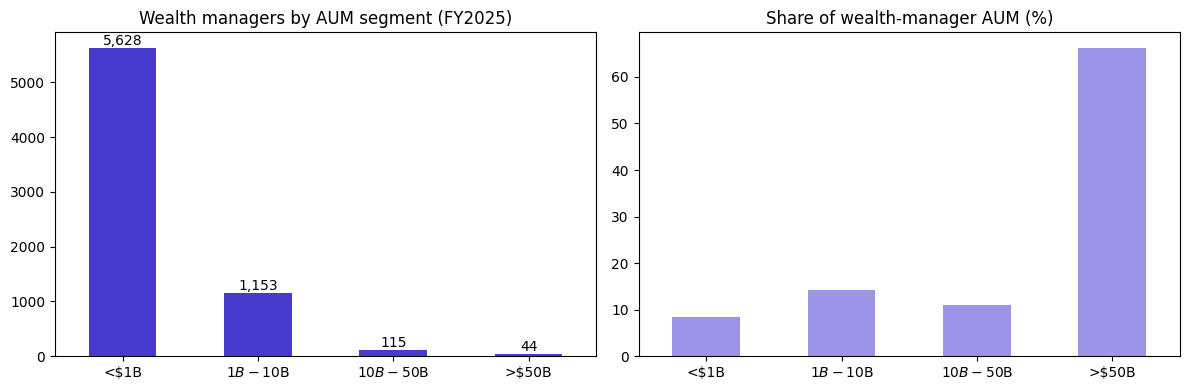

In [12]:
wm_seg = latest[wmask].groupby("segment", observed=False).agg(firms=("crd", "count"), aum=("aum", lambda x: x.sum() / 1e12))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
wm_seg.firms.plot.bar(ax=ax[0], color="#473BCE"); ax[0].set_title("Wealth managers by AUM segment (FY2025)")
for i, v in enumerate(wm_seg.firms): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
(wm_seg.aum / wm_seg.aum.sum() * 100).plot.bar(ax=ax[1], color="#9C94E6"); ax[1].set_title("Share of wealth-manager AUM (%)")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Commentary.**
* **All RIAs vs wealth managers:** two-thirds of SEC RIAs are under \$1B, and the 432 firms above \$50B hold 79% of all assets. But that top tier is overwhelmingly asset managers. Only **44 of the 432 are wealth managers**.
* **The Nevis market is 6,940 wealth managers.** About 1,300 are above \$1B and **159 are Enterprise-scale (\$10B+)**: short enough for named-account selling. The ~5,600 firms under \$1B suit a product-led motion.
* **Dual-registered firms** (wirehouses, IBDs) are few in number (224) but enormous in scale: Morgan Stanley, Merrill, Edward Jones, UBS, LPL and Wells Fargo Advisors account for most wealth-manager AUM above \$50B.

# 3. Question 2a: Who are the fastest-growing firms?
AUM CAGR over 1 year (FY2024→FY2025), 3 years (FY2022→FY2025) and 5 years (FY2020→FY2025), sustained growth only (inorganic step-changes shown separately).

In [13]:
print("Fastest-growing wealth managers: 3-year AUM CAGR (FY2022→FY2025)"); fmt(fast_wm[3])

Fastest-growing wealth managers: 3-year AUM CAGR (FY2022→FY2025)


,segment,firm_name,channel,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager
11298,$1B-$10B,49 FINANCIAL,Independent RIA,TX,0.23,1.40,82.60,68.30,True
2010,$10B-$50B,"WAVERLY ADVISORS, LLC",Independent RIA,AL,5.78,29.87,72.90,60.80,True
8769,$1B-$10B,ARKADIOS WEALTH ADVISORS,Independent RIA,GA,1.76,8.79,71.00,56.70,True
8500,$1B-$10B,"WISS PRIVATE CLIENT ADVISORS, LLC",Independent RIA,NJ,0.25,1.22,70.10,55.90,True
1830,<$1B,"MWA FINANCIAL SERVICES, INC.",Dual-registered (broker-dealer),IL,0.14,0.64,67.70,54.90,True
8229,$1B-$10B,"CLARK ASSET MANAGEMENT, LLC",Independent RIA,NaN,0.28,1.32,67.50,53.20,True
7934,$1B-$10B,AERODIGM WEALTH LLC,Independent RIA,OR,0.32,1.46,66.40,52.10,True
9158,<$1B,MAIA WEALTH,Independent RIA,CO,0.21,0.97,65.80,52.90,True
7127,$10B-$50B,APELLA WEALTH,Independent RIA,CT,2.48,11.07,64.70,52.60,True
4570,>$50B,PATHSTONE,Independent RIA,NJ,24.84,110.30,64.40,50.90,True


In [14]:
print("Fastest-growing wealth managers: 1-year AUM growth (FY2024→FY2025)"); fmt(fast_wm[1])

Fastest-growing wealth managers: 1-year AUM growth (FY2024→FY2025)


,segment,firm_name,channel,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager
13013,<$1B,"SAND CREEK CAPITAL, LLC",Independent RIA,ID,0.19,0.47,144.10,130.00,True
6939,<$1B,TENCAP WEALTH COACHING,Independent RIA,UT,0.12,0.29,143.20,129.10,True
12640,$1B-$10B,"ASCENTIS INDEPENDENT ADVISORS, LLC",Independent RIA,TX,0.88,2.09,137.90,123.00,True
12071,<$1B,"DISCIPLINE WEALTH SOLUTIONS, INC.",Independent RIA,SC,0.32,0.75,136.10,122.00,True
5117,<$1B,INTEGRITY INVESTMENT ADVISORS,Independent RIA,NaN,0.17,0.39,134.70,120.60,True
7610,$10B-$50B,APELLA WEALTH,Independent RIA,CT,4.71,11.07,134.70,120.60,True
3447,<$1B,"HERBERT J. SIMS CAPITAL MANAGEMENT, INC.",Independent RIA,CT,0.19,0.44,133.90,119.90,True
13767,<$1B,"MARTIN, JAVAN VON",Independent RIA,NaN,0.41,0.95,133.50,119.40,True
13728,<$1B,"PARADIGM INVESTMENT ADVISORY, LLC",Independent RIA,NJ,0.18,0.43,132.50,118.40,True
11089,<$1B,RETIRABLE,Independent RIA,NY,0.13,0.30,130.40,116.30,True


In [15]:
print("Fastest-growing wealth managers: 5-year AUM CAGR (FY2020→FY2025)"); fmt(fast_wm[5])

Fastest-growing wealth managers: 5-year AUM CAGR (FY2020→FY2025)


,segment,firm_name,channel,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager
8295,$1B-$10B,ARKADIOS WEALTH ADVISORS,Independent RIA,GA,0.81,8.79,61.00,49.80,True
8003,$1B-$10B,FACET,Independent RIA,FL,0.81,7.60,56.60,45.40,True
1992,$10B-$50B,"WAVERLY ADVISORS, LLC",Independent RIA,AL,3.29,29.87,55.40,46.10,True
8629,<$1B,MAIA WEALTH,Independent RIA,CO,0.11,0.97,54.80,46.70,True
7878,$1B-$10B,THE FIDUCIARY ALLIANCE,Independent RIA,SC,0.30,2.53,52.90,41.80,True
3655,$10B-$50B,MERIT FINANCIAL ADVISORS,Dual-registered (broker-dealer),GA,2.88,23.88,52.70,43.30,True
1122,$1B-$10B,"T. ROWE PRICE ADVISORY SERVICES, INC.",Independent RIA,MD,0.73,5.90,51.90,40.80,True
8214,<$1B,"LIFEWORKS ADVISORS, LLC",Independent RIA,MI,0.12,0.97,51.20,43.10,True
8258,>$50B,"CRESSET ASSET MANAGEMENT, LLC",Independent RIA,IL,11.68,78.94,46.60,36.10,True
8532,>$50B,ROCKEFELLER CAPITAL MANAGEMENT,Dual-registered (broker-dealer),NY,14.86,99.60,46.30,35.90,True


In [16]:
print("Inorganic / step-change movers, 3-year (acquisitions, re-registrations, roll-ups): advisor-led wealth managers")
fmt(inorganic_wm)

Inorganic / step-change movers, 3-year (acquisitions, re-registrations, roll-ups): advisor-led wealth managers


,segment,firm_name,channel,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager,adv_start,adv_end
11225,$1B-$10B,"VESTGEN ADVISORS, LLC",Independent RIA,IL,0.53,6.67,132.80,118.50,True,7.00,58.00
3215,$1B-$10B,PROSPERITY - AN EISNERAMPER COMPANY,Independent RIA,MD,0.41,5.04,131.40,117.10,True,8.00,60.00
7196,$1B-$10B,"COMPOUND PLANNING, INC.",Independent RIA,NY,0.43,4.85,124.30,110.00,True,18.00,76.00
10843,$1B-$10B,"IMPACT PARTNERSHIP WEALTH, LLC",Independent RIA,GA,0.29,2.96,116.50,102.30,True,33.00,89.00
5588,>$50B,"FOCUS PARTNERS WEALTH, LLC",Independent RIA,MO,18.83,181.86,113.00,99.50,True,215.00,"1,025.00"
11387,<$1B,ENCOMPASS MORE ASSET MANAGEMENT LLC,Independent RIA,CA,0.11,0.98,105.60,92.70,True,32.00,85.00
11553,<$1B,CANOPY PARTNERS,Independent RIA,OH,0.10,0.87,102.40,89.60,True,1.00,3.00
7683,>$50B,"OSAIC WEALTH, INC.",Dual-registered (broker-dealer),AZ,29.54,234.86,99.60,86.20,True,"2,075.00","7,143.00"
8237,$1B-$10B,ONEASCENT FINANCIAL SERVICES LLC,Independent RIA,AL,0.46,3.54,97.90,83.60,True,25.00,74.00
310,>$50B,CETERA INVESTMENT ADVISERS LLC,Independent RIA,IL,33.36,256.81,97.50,84.00,True,"2,788.00","9,049.00"


**Commentary.**
* **Sustained growth at scale:** multi-billion-dollar wealth managers compounding at 60-70%+ a year (Waverly, Arkadios, Apella, Pathstone, Merit). Growth more than 50pp above the segment median shows this isn't just the market.
* **The inorganic list is a sales signal in its own right.** Firms that grew by acquisition or consolidation (Focus Partners, Osaic, Cetera) are integrating acquired teams, each with its own workflows and tech stack. See Section 6.2.
* The 1-year view is noisier and is best read alongside the 3- and 5-year views. Lists for all RIAs (including asset managers) are in the Excel file.

# 4. Question 2b: Which firms are capacity-strained?
Measured on FY2025 data, firms with at least 3 advisors (so single-person shops don't dominate). Shown for all RIAs (the literal answer) and for wealth managers, where **clients per advisor** is shown too. For a wealth manager, clients per advisor is the truer measure of strain, because advisor time scales with relationships, not dollars.

In [17]:
print("Highest AUM per advisor: wealth managers (FY2025, 3+ advisors)"); fmt(cap_wm)

Highest AUM per advisor: wealth managers (FY2025, 3+ advisors)


,segment,firm_name,channel,state,AUM $B,advisors,iars,AUM/advisor $M,clients_per_advisor,Retail AUM %
86366,$1B-$10B,"PROWELL FINANCIAL MANAGEMENT, LLC",Independent RIA,PA,6.86,3.00,3.00,"2,288.00",24.67,97.30
81543,$1B-$10B,"WHARTON BUSINESS GROUP, LLC",Independent RIA,PA,4.57,3.00,3.00,"1,522.00",41.33,81.70
81017,$1B-$10B,YALE CAPITAL CORP.,Independent RIA,FL,5.62,4.00,5.00,"1,405.00",29.50,100.00
82185,$10B-$50B,"CIRCLE WEALTH MANAGEMENT, LLC",Independent RIA,NJ,14.07,11.00,10.00,"1,279.00",34.77,92.80
80775,$1B-$10B,"FRANK, RIMERMAN ADVISORS LLC",Independent RIA,CA,3.40,3.00,2.00,"1,133.00",36.17,99.80
78356,$1B-$10B,ACCREDITED INVESTORS WEALTH MANAGEMENT,Independent RIA,MN,4.41,4.00,4.00,"1,103.00",236.75,99.50
79113,$1B-$10B,"MILLER INVESTMENT MANAGEMENT, LP",Independent RIA,PA,7.10,7.00,6.00,"1,015.00",26.50,88.80
78796,$10B-$50B,"LORING, WOLCOTT & COOLIDGE FIDUCIARY ADVISORS,...",Independent RIA,MA,12.84,13.00,10.00,987.00,253.27,94.50
92453,$1B-$10B,L 1 GLOBAL WEALTH LLC,Independent RIA,FL,2.81,3.00,4.00,937.00,5.67,100.00
85069,$1B-$10B,"COLONY FAMILY OFFICES, LLC",Independent RIA,NC,3.36,4.00,7.00,841.00,164.00,95.90


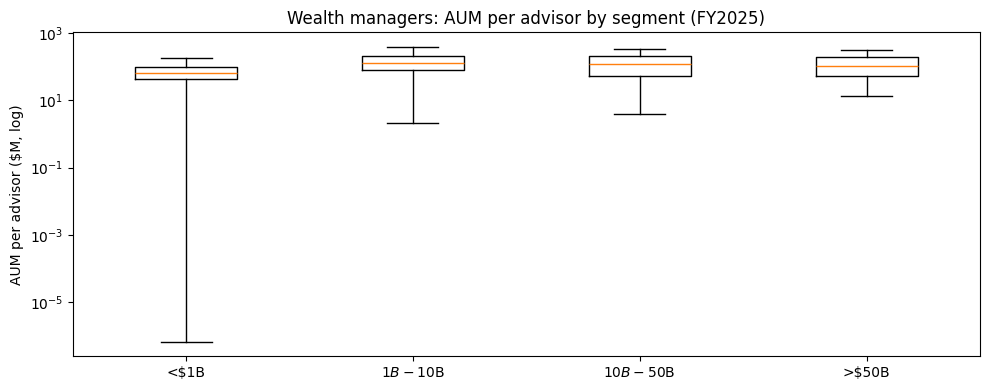

,median AUM/advisor $M,clients_per_advisor
segment,,
<$1B,64.61,62.00
$1B-$10B,130.03,66.97
$10B-$50B,122.76,61.59
>$50B,106.89,78.64


In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
data = [cap[(cap.segment == s) & cap.wealth_manager].aum_per_advisor.dropna() / 1e6 for s in LABELS]
ax.boxplot(data, labels=LABELS, showfliers=False); ax.set_yscale("log")
ax.set_ylabel("AUM per advisor ($M, log)"); ax.set_title("Wealth managers: AUM per advisor by segment (FY2025)")
plt.tight_layout(); plt.show()
cap_medians

**Commentary.**
* **Typical load:** a \$1B+ wealth manager runs about \$120M-\$130M of AUM and 60-80 clients per advisor (table above). Firms far above this are the most stretched.
* **Two kinds of strain.** High AUM per advisor with few clients (Circle Wealth, Prowell, First Manhattan) usually means ultra-high-net-worth or family-office models: fewer, deeper relationships where the pain is preparation and reporting quality. High clients per advisor (150-300+) means volume pain: meetings, follow-ups and compliance notes. Each suggests a different Nevis pitch.
* All-RIA rankings (which are dominated by fund complexes such as Vanguard) are in the Excel file.

# 5. Question 3: Which RIAs appear under-staffed?
**Staffing gap = AUM CAGR minus advisor-headcount CAGR** over 1, 3 and 5 years. A positive gap means each advisor is carrying more AUM every year. Requires at least 3 advisors at the start of the window (so 1→2 hires don't create noise) and the segment minimum starting AUM, and excludes inorganic step-changes.

In [19]:
print("Under-staffed wealth managers: 3-year (FY2022→FY2025)"); fmt(gap_wm[3])

Under-staffed wealth managers: 3-year (FY2022→FY2025)


,segment,firm_name,channel,state,AUM end $B,AUM CAGR %,Advisor CAGR %,Gap (pp),adv_start,adv_end,wealth_manager
8500,$1B-$10B,"WISS PRIVATE CLIENT ADVISORS, LLC",Independent RIA,NJ,1.22,70.10,4.00,66.10,8.00,9.00,True
8434,$1B-$10B,FACET,Independent RIA,FL,7.60,54.10,-10.90,65.00,109.00,77.00,True
8769,$1B-$10B,ARKADIOS WEALTH ADVISORS,Independent RIA,GA,8.79,71.00,9.50,61.50,115.00,151.00,True
8957,<$1B,"FORTRESS PRIVATE LEDGER, LLC",Dual-registered (broker-dealer),NC,0.58,60.30,0.00,60.30,13.00,13.00,True
8760,$1B-$10B,"KINGSWOOD WEALTH ADVISORS, LLC",Independent RIA,CA,3.80,57.70,-0.90,58.50,78.00,76.00,True
9836,<$1B,CONVERGENCE FINANCIAL,Independent RIA,MO,0.90,44.70,-13.40,58.10,20.00,13.00,True
9032,<$1B,"REDWOOD FINANCIAL PLANNING, LLC",Independent RIA,NJ,0.39,56.60,0.00,56.60,3.00,3.00,True
8764,<$1B,"BEACON GLOBAL ADVISOR NETWORK, LLC",Independent RIA,GA,0.75,63.90,10.70,53.20,45.00,61.00,True
5056,<$1B,ALPHA SOLUTIONS INVESTMENT ADVISORS,Independent RIA,CA,0.47,61.70,10.10,51.70,3.00,4.00,True
10608,<$1B,"RETIREMENT PLANNING SOLUTIONS, LLC",Independent RIA,KY,0.47,33.80,-17.80,51.60,9.00,5.00,True


In [20]:
print("Under-staffed wealth managers: 1-year (FY2024→FY2025)"); fmt(gap_wm[1])

Under-staffed wealth managers: 1-year (FY2024→FY2025)


,segment,firm_name,channel,state,AUM end $B,AUM CAGR %,Advisor CAGR %,Gap (pp),adv_start,adv_end,wealth_manager
6939,<$1B,TENCAP WEALTH COACHING,Independent RIA,UT,0.29,143.20,-22.20,165.40,9.00,7.00,True
13450,<$1B,"OUTRUNNER CAPITAL, LLC",Independent RIA,TX,0.50,113.70,-40.00,153.70,5.00,3.00,True
12925,$1B-$10B,BRIDGEPORT FINANCIAL SOLUTIONS,Independent RIA,AZ,1.05,116.00,-18.20,134.20,11.00,9.00,True
3447,<$1B,"HERBERT J. SIMS CAPITAL MANAGEMENT, INC.",Independent RIA,CT,0.44,133.90,4.20,129.80,24.00,25.00,True
9429,$1B-$10B,ARKADIOS WEALTH ADVISORS,Independent RIA,GA,8.79,127.90,0.00,127.90,151.00,151.00,True
13312,<$1B,VERIDAN WEALTH,Independent RIA,OR,0.67,119.00,0.00,119.00,4.00,4.00,True
9464,<$1B,BLACKTOWER FINANCIAL MANAGEMENT (US) LLC,Independent RIA,FL,0.25,107.10,-9.70,116.80,31.00,28.00,True
5115,<$1B,"PATHWAYS WEALTH MANAGEMENT, INC.",Independent RIA,NaN,0.29,115.30,0.00,115.30,3.00,3.00,True
12960,<$1B,MDRN CAPITAL,Independent RIA,MD,0.34,110.50,-4.30,114.90,23.00,22.00,True
10626,$10B-$50B,FARTHER,Independent RIA,CA,16.01,112.80,0.80,112.00,250.00,252.00,True


In [21]:
print("Under-staffed wealth managers: 5-year (FY2020→FY2025)"); fmt(gap_wm[5])

Under-staffed wealth managers: 5-year (FY2020→FY2025)


,segment,firm_name,channel,state,AUM end $B,AUM CAGR %,Advisor CAGR %,Gap (pp),adv_start,adv_end,wealth_manager
8003,$1B-$10B,FACET,Independent RIA,FL,7.60,56.60,0.00,56.60,77.00,77.00,True
8974,<$1B,CASTELLAN,Independent RIA,KY,0.88,42.50,0.00,42.50,4.00,4.00,True
5343,<$1B,"PARK CAPITAL MANAGEMENT, LLC",Independent RIA,WI,0.87,37.50,-3.60,41.10,6.00,5.00,True
3687,$10B-$50B,"CIRCLE WEALTH MANAGEMENT, LLC",Independent RIA,NJ,14.07,38.40,0.00,38.40,11.00,11.00,True
6494,<$1B,FISCAL WISDOM WEALTH MANAGEMENT LLC,Independent RIA,CT,0.39,28.80,-9.00,37.80,16.00,10.00,True
8629,<$1B,MAIA WEALTH,Independent RIA,CO,0.97,54.80,17.60,37.20,16.00,36.00,True
8959,<$1B,"WICK CAPITAL PARTNERS, LLC",Independent RIA,PA,0.93,33.50,-3.60,37.10,12.00,10.00,True
1122,$1B-$10B,"T. ROWE PRICE ADVISORY SERVICES, INC.",Independent RIA,MD,5.90,51.90,15.60,36.30,32.00,66.00,True
3831,<$1B,"REAP FINANCIAL GROUP, LLC",Independent RIA,TX,0.65,22.50,-12.90,35.50,12.00,6.00,True
8037,<$1B,"WHITAKER-MYERS WEALTH MANAGERS, LTD.",Independent RIA,OH,0.85,37.40,2.10,35.30,9.00,10.00,True


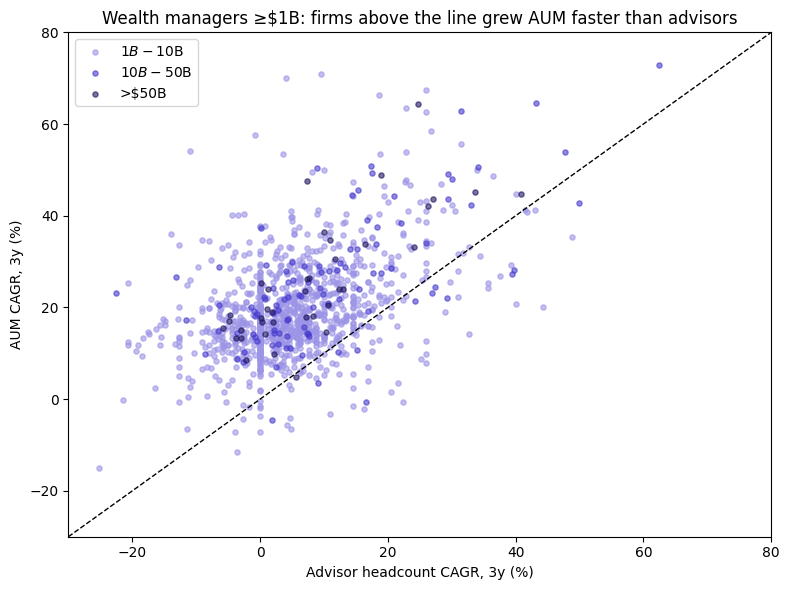

$1B+ advisor-led wealth managers: 1,152 | grew AUM faster than advisors: 92% | median AUM CAGR 18.1% vs advisor CAGR 4.6%


In [22]:

fig, ax = plt.subplots(figsize=(8, 6))
for s, c in zip(LABELS[1:], ["#9C94E6", "#473BCE", "#1E1660"]):
    d = w3[w3.segment == s]; ax.scatter(d.advisor_cagr * 100, d.aum_cagr * 100, s=14, alpha=.6, label=s, color=c)
lim = [-30, 80]; ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Advisor headcount CAGR, 3y (%)"); ax.set_ylabel("AUM CAGR, 3y (%)")
ax.set_title("Wealth managers ≥$1B: firms above the line grew AUM faster than advisors"); ax.legend()
plt.tight_layout(); plt.show()
print(f"$1B+ advisor-led wealth managers: {len(w3):,} | grew AUM faster than advisors: {(w3.staffing_gap > 0).mean():.0%}"
      f" | median AUM CAGR {w3.aum_cagr.median():.1%} vs advisor CAGR {w3.advisor_cagr.median():.1%}")

**Commentary.**
* **Under-staffing is the norm, not the exception:** 92% of \$1B+ wealth managers sit above the diagonal; median AUM growth of 18.1% a year vs 4.6% for advisors. The industry's well-known advisor shortage shows up directly in the ADV data.
* **The clearest cases** grew AUM 50-70% a year with flat or falling advisor headcount (Wiss, Facet, Arkadios, Kingswood). They have the budget, and the strongest need for more leverage per advisor.

# 6. Additional data of value
## 6.1 Which custodians do the largest firms use?
Source: Schedule D 5.K(3), each firm's latest filing to Dec 2024 (see Step 1b). Firms list every custodian holding **≥10% of their separately managed account AUM**, so a firm can show several. Shares are **% of firms in the group that use each custodian**.

In [23]:
for name, (tbl, coverage, n) in cust_tables.items():
    print(f"\n{name}: {n:,} firms, {coverage:.0%} report a custodian")
    display(tbl.head(8).assign(share_of_firms=lambda x: (x.share_of_firms * 100).round(0), aum_held_bn=lambda x: x.aum_held_bn.round(0))
            .rename(columns={"share_of_firms": "% of firms", "aum_held_bn": "SMA AUM held $B"}))


All RIAs >$50B: 432 firms, 67% report a custodian


,firms,SMA AUM held $B,% of firms
custodian,,,
BNY,133,"3,693.00",31.00
State Street,111,"2,011.00",26.00
Northern Trust,78,"1,497.00",18.00
J.P. Morgan,70,"2,197.00",16.00
Fidelity,43,"1,607.00",10.00
Charles Schwab,33,811.00,8.00
Citi,29,764.00,7.00
U.S. Bank,23,309.00,5.00



Wealth managers >$50B: 44 firms, 86% report a custodian


,firms,SMA AUM held $B,% of firms
custodian,,,
Fidelity,24,597.00,55.00
Charles Schwab,18,505.00,41.00
Pershing (BNY),7,274.00,16.00
Raymond James,3,566.00,7.00
J.P. Morgan,1,185.00,2.00
Vanguard,1,311.00,2.00
Truist,1,9.00,2.00
State Street,1,11.00,2.00



Wealth managers $10B-$50B: 115 firms, 90% report a custodian


,firms,SMA AUM held $B,% of firms
custodian,,,
Charles Schwab,65,318.00,57.00
Fidelity,62,324.00,54.00
Pershing (BNY),20,137.00,17.00
LPL Financial,10,108.00,9.00
J.P. Morgan,3,7.00,3.00
Raymond James,3,16.00,3.00
Axos Clearing Llc,2,1.00,2.00
SEI,2,7.00,2.00



Wealth managers $1B-$10B: 1,153 firms, 93% report a custodian


,firms,SMA AUM held $B,% of firms
custodian,,,
Charles Schwab,749,864.00,65.00
Fidelity,413,422.00,36.00
Pershing (BNY),108,133.00,9.00
LPL Financial,51,74.00,4.00
Raymond James,39,46.00,3.00
Wells Fargo,23,24.00,2.00
BNY,17,16.00,1.00
SEI,16,7.00,1.00


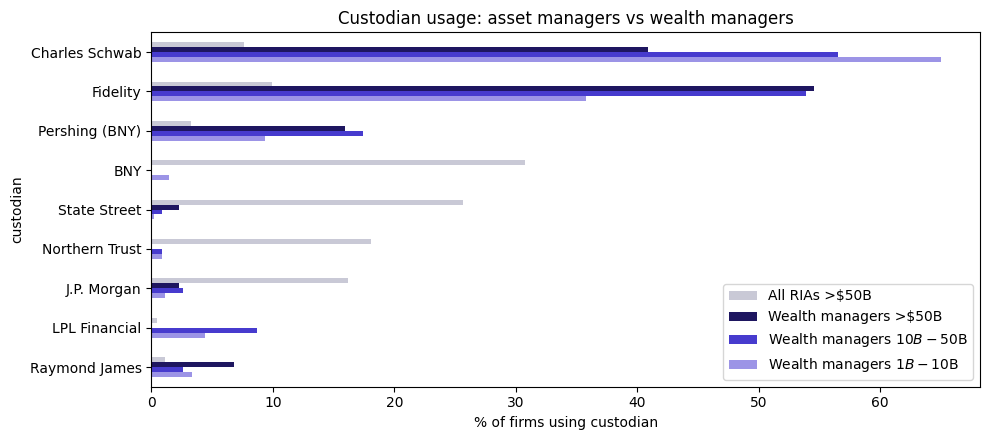

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.5))
views = ["All RIAs >$50B", "Wealth managers >$50B", "Wealth managers $10B-$50B", "Wealth managers $1B-$10B"]
top = ["Charles Schwab", "Fidelity", "Pershing (BNY)", "BNY", "State Street", "Northern Trust", "J.P. Morgan", "LPL Financial", "Raymond James"]
mat = pd.DataFrame({v: cust_tables[v][0].reindex(top).share_of_firms.fillna(0) * 100 for v in views})
mat.plot.barh(ax=ax, color=["#C9C9D6", "#1E1660", "#473BCE", "#9C94E6"]); ax.invert_yaxis()
ax.set_xlabel("% of firms using custodian"); ax.set_title("Custodian usage: asset managers vs wealth managers"); plt.tight_layout(); plt.show()

**Commentary.**
* **Two different worlds:** asset managers (all RIAs >\$50B) custody with BNY, State Street and Northern Trust. Wealth managers custody overwhelmingly with **Schwab and Fidelity**, plus Pershing.
* **Schwab and Fidelity each serve over half of \$10B+ wealth managers**, and Schwab ~65% of \$1B-\$10B firms. A partnership or integration with these custodians' advisor platforms would reach most of Nevis's market.
* **Caveat:** custodians are reported only if they hold ≥10% of a firm's separately managed account AUM, and come from filings up to Dec 2024.

## 6.2 Ownership change: roll-ups likely to want to coordinate technology
A firm that has changed hands, or is acquiring others, has a clear reason to standardise its technology: new owners and acquired teams bring different workflows, CRMs and processes. Signals for **wealth managers with \$1B+ AUM**, from each firm's latest filing to Dec 2024:

| Signal | Source | What it indicates |
|---|---|---|
| **New controlling entity since 2020** | Schedules A/B: an entity (not an individual) with 25%+ ownership or control, acquired 2020 or later | Sale to a PE sponsor, strategic acquirer or new holding structure |
| **Likely PE sponsor** | Name of that new controlling entity (L.P., Partners, Equity, Investors, Aggregator, Co-Invest, Fund) | Financial-sponsor ownership, typically with a buy-and-build (roll-up) strategy |
| **Succession since 2020** | Schedule D Section 4 | The firm took over another registered adviser's business |
| **Ownership layers** | Count of Schedule B indirect owners | Complex holding structures typical of sponsor-backed platforms |

In [25]:
print("Share of $1B+ wealth managers showing each ownership-change signal, by segment")
display((own_summary.drop(columns="wealth_managers") * 100).round(0).astype(int).assign(wealth_managers=own_summary.wealth_managers))
print("\nLargest wealth managers with a new controlling entity since 2020")
show = own[own.new_controlling_entity_since_2020.fillna(False).astype(bool)].sort_values("aum", ascending=False).groupby("segment", observed=True, group_keys=False).head(10)
show.assign(aum=(show.aum / 1e9).round(1)).rename(columns={"aum": "AUM $B"})[
    ["segment", "firm_name", "channel", "state", "AUM $B", "advisors", "likely_pe_sponsor_owner", "control_acquired_date", "successions_since_2020", "sponsor_names", "new_controlling_entities"]]

Share of $1B+ wealth managers showing each ownership-change signal, by segment


,ownership_change,new_controlling_entity,likely_pe_sponsor,any_succession,wealth_managers
segment,,,,,
$1B-$10B,23,21,6,4,1153
$10B-$50B,47,46,25,8,115
>$50B,50,50,22,7,44



Largest wealth managers with a new controlling entity since 2020


,segment,firm_name,channel,state,AUM $B,advisors,likely_pe_sponsor_owner,control_acquired_date,successions_since_2020,sponsor_names,new_controlling_entities
crd,,,,,,,,,,,
149777,>$50B,MORGAN STANLEY,Dual-registered (broker-dealer),NY,"1,961.90","13,000.00",False,2023-08,0.00,NaN,"MORGAN STANLEY CAPITAL MANAGEMENT, LLC"
250,>$50B,EDWARD JONES,Dual-registered (broker-dealer),MO,"1,013.60","20,304.00",False,2020-11,0.00,NaN,"JFC HOLDING COMPANY, INC.; THE JONES FINANCIAL..."
105348,>$50B,CREATIVE PLANNING,Independent RIA,KS,295.60,"1,538.00",False,2024-11,1.00,NaN,"CPI HOLDCO A, LLC; CPI HOLDCO B, LLC; CREATIVE..."
23131,>$50B,"OSAIC WEALTH, INC.",Dual-registered (broker-dealer),AZ,234.90,"7,143.00",False,2020-05,0.00,NaN,AG INTERMEDIATE CORPORATION; OSAIC FINANCIAL S...
8032,>$50B,COMMONWEALTH FINANCIAL NETWORK,Dual-registered (broker-dealer),MA,212.70,"2,650.00",False,2024-03,0.00,NaN,"GRATITUDE HOLDINGS, INC.; JOSEPH S. DEITCH 200..."
145323,>$50B,"HIGHTOWER ADVISORS, LLC",Independent RIA,IL,198.60,953.00,True,2020-12,0.00,"THL EQUITY FUND VII INVESTORS (HT) BLOCKER, LL...","HIGHTOWER INTERMEDIATE, LLC; HT HOLDING, LLC; ..."
112058,>$50B,"EMPOWER ADVISORY GROUP, LLC",Independent RIA,CO,195.40,"6,138.00",False,2024-01,1.00,NaN,EMPOWER ANNUITY INSURANCE COMPANY OF AMERICA; ...
159289,>$50B,"FOCUS PARTNERS WEALTH, LLC",Independent RIA,MO,181.90,"1,025.00",True,2023-08,0.00,"CD&R ASSOCIATES XII, L.P.; CD&R FERDINAND CO-I...","CD&R ASSOCIATES XII, L.P.; CD&R FERDINAND CO-I..."
319448,>$50B,CORIENT,Independent RIA,FL,165.30,620.00,False,2023-12,1.00,NaN,CORIENT HOLDINGS INC; CORIENT MANAGEMENT LLC; ...


**Commentary.**
* **Ownership change is concentrated at the top:** about half of \$10B+ wealth managers have a new controlling entity since 2020, vs about a quarter of \$1B-\$10B firms.
* **PE-backed platforms** (Focus Partners and SCS/CD&R, Hightower/THL, Mariner/Leonard Green, Cerity/Genstar) are executing buy-and-build strategies. Each acquisition adds advisors with different tools and workflows, which is a strong trigger for standardised meeting prep, notes and CRM hygiene.
* **Caveat:** the PE flag is a name-based heuristic. New owners named "Holdings" or "Holdco" (e.g. Creative Planning's new owners) count as ownership change but not as PE.

## 6.3 Bringing it together: a prioritised Nevis target list
The three signals combined into one score for **US advisor-led wealth managers with 5+ advisors**, ranked within each segment by percentile (equal weights):
1. **3-year AUM CAGR**: momentum and budget.
2. **AUM per advisor (Sep 2026)**: current capacity strain.
3. **3-year staffing gap**: strain that is getting worse.

In [26]:
targets = targets.join(t["crd"]).join(ref["ownership"][["new_controlling_entity_since_2020", "likely_pe_sponsor_owner"]], on="crd").drop(columns="crd")
fmt(targets).rename(columns={"adv_end": "advisors"})

,segment,firm_name,channel,website,website_confidence,city,state,AUM end $B,AUM CAGR %,AUM/advisor $M,clients_per_advisor,Gap (pp),advisors,inorganic_flag,nevis_score,new_controlling_entity_since_2020,likely_pe_sponsor_owner
8725,>$50B,"CRESSET ASSET MANAGEMENT, LLC",Independent RIA,www.cressetpartners.com,name match,Chicago,IL,78.94,47.50,422.00,26.26,40.10,187.00,False,93.80,False,False
4570,>$50B,PATHSTONE,Independent RIA,www.pathstone.com,verified,Englewood,NJ,110.30,64.40,302.00,6.15,39.60,365.00,False,93.02,True,True
5588,>$50B,"FOCUS PARTNERS WEALTH, LLC",Independent RIA,www.focuspartners.com,verified,St. Louis,MO,181.86,113.00,177.00,60.94,44.70,"1,025.00",True,88.37,True,True
1284,>$50B,"MAI CAPITAL MANAGEMENT, LLC",Independent RIA,www.mai.capital,name match,Cleveland,OH,52.10,48.90,227.00,70.75,30.10,230.00,False,87.60,True,False
4906,>$50B,"CWM, LLC",Independent RIA,www.carsonwealth.com,verified,Omaha,NE,50.58,36.40,107.00,111.59,26.30,472.00,False,72.09,True,True
721,>$50B,SAVANT WEALTH MANAGEMENT,Independent RIA,www.savantwealth.com,name match,Rockford,IL,55.61,43.80,234.00,100.98,16.70,238.00,False,72.09,True,False
9795,>$50B,"IEQ CAPITAL, LLC",Independent RIA,www.ieqcapital.com,name match,Foster City,CA,56.77,45.20,294.00,11.96,11.70,193.00,False,70.54,True,False
7683,>$50B,"OSAIC WEALTH, INC.",Dual-registered (broker-dealer),www.osaic.com,verified,Scottsdale,AZ,234.86,99.60,33.00,80.57,48.60,"7,143.00",True,70.54,True,False
744,>$50B,FISHER INVESTMENTS,Independent RIA,www.fisherinvestments.com,verified,Plano,TX,386.67,26.20,198.00,102.63,18.80,"1,948.00",False,69.77,False,False
1371,>$50B,WELLS FARGO ADVISORS,Dual-registered (broker-dealer),www.wellsfargo.com,name match,St. Louis,MO,252.25,34.70,107.00,197.20,23.70,"2,366.00",False,68.99,False,False


**How to use this list.** The score is a prioritisation aid, not a verdict:
* **\$50B+ (Enterprise):** Cresset, Pathstone, Focus Partners, MAI, Savant, Carson, IEQ and Fisher combine scale, strong growth and rising AUM per advisor. Osaic and Cetera are a different motion: very large networks with low AUM per advisor, where the opportunity is giving thousands of independent advisors consistent tooling.
* **\$10B-\$50B:** Aptus, RWA, Clearstead, Merit, Apella, Apollon, NewEdge and Steward are fast-growing aggregators or multi-office firms, an ideal mid-market Enterprise wedge.
* **Next step to sharpen it:** add custodian (Schedule D 5.K(3)), tech-stack signals and recent M&A announcements, then validate the top 20 with account research before outreach.

# 7. Export

In [27]:
with pd.ExcelWriter(OUT / "nevis_ria_targets.xlsx") as xw:
    fmt(targets).to_excel(xw, sheet_name="Nevis targets", index=False)
    seg.reset_index().to_excel(xw, sheet_name="Segments", index=False)
    summary.reset_index().to_excel(xw, sheet_name="Data checks", index=False)
    for h in (1, 3, 5):
        fmt(top_by_segment(win[h], "aum_cagr", n=25, wealth_only=True, cols=G, organic=True)).to_excel(xw, sheet_name=f"Fastest growth {h}y (WMs)", index=False)
        fmt(top_by_segment(win[h], "staffing_gap", n=25, wealth_only=True, cols=S, organic=True)).to_excel(xw, sheet_name=f"Under-staffed {h}y (WMs)", index=False)
        fmt(top_by_segment(win[h], "aum_cagr", n=25, cols=G, organic=True)).to_excel(xw, sheet_name=f"Fastest growth {h}y (all)", index=False)
        fmt(top_by_segment(win[h], "staffing_gap", n=25, cols=S, organic=True)).to_excel(xw, sheet_name=f"Under-staffed {h}y (all)", index=False)
    fmt(top_by_segment(cap, "aum_per_advisor", n=25, cols=C)).to_excel(xw, sheet_name="Capacity (all)", index=False)
    fmt(top_by_segment(cap, "aum_per_advisor", n=25, wealth_only=True, cols=C)).to_excel(xw, sheet_name="Capacity (wealth mgrs)", index=False)
    pd.concat({k: v[0].head(15) for k, v in cust_tables.items()}).reset_index().to_excel(xw, sheet_name="Custodians", index=False)
    own.reset_index().to_excel(xw, sheet_name="Ownership change ($1B+ WMs)", index=False)
    latest.drop(columns=["segment"]).assign(segment=latest.segment.astype(str)).to_excel(xw, sheet_name="Firm table (2026)", index=False)
print("Saved:", list(OUT.iterdir()))

Saved: [PosixPath('outputs/nevis_ria_targets.xlsx'), PosixPath('outputs/ria_firm_year_table.csv')]
